# EEG-Based Deep Sleep Quality Assessment
### VS Code edition — ISRUC-III dataset (10 patients, .rec files), every stage visualized

Instead of running all the processing first and plotting at the end, this notebook follows the
**data through the pipeline** and visualizes the result of *each* stage as it happens:

`raw signal → band-pass → normalize → delta power → epoching → features → model → training → evaluation → inference`

**Dataset: ISRUC Sleep Study Sub-Group III**
- 10 patients (healthy subjects with sleep disorders)
- `.rec` files (EDF-compatible format via MNE)
- Annotation: `*_1.txt` (text) and `*_1.xlsx` (Excel) files
- Sampling rate: 200 Hz
- EEG channel: `C4-A1` (or `F4-A1` fallback)
- Sleep stages: W, N1, N2, N3, REM (AASM 2007)

| Diagram block | Notebook section |
|---|---|
| Input & Preprocessing | §2 (signal) and §3 (filter → normalize → delta) |
| Epoching & dataset | §4 |
| Feature validation | §5 |
| Backbone + Dual-Task Heads | §6 |
| Multi-Task Loss + training | §7 |
| Evaluation & explainability | §8–§9 |
| Inference | §10 |


## 1. Setup

In [1]:
import os

# ── Trailing space in folder name! ──────────────────────────────────────────
PROJECT_DIR = "/Users/alampranto/Desktop/eeg sleeping/project of eeg sleep detect "  # <-- trailing space

print("=== Inside 'project of eeg sleep detect '/ ===")
for item in sorted(os.listdir(PROJECT_DIR)):
    print(f"  {repr(item)}")

=== Inside 'project of eeg sleep detect '/ ===
  '.DS_Store'
  'ISRUC-Sleep-III'
  '__pycache__'
  'code save.ipynb'
  'data'
  'diagram-export-5-23-2026-11_23_07-AM.png'
  'files'
  'isruc3_xai_fixed.ipynb'
  'isruc3_xai_local (1).ipynb'
  'sleep_quality_model.py'


In [2]:
import os, shutil, mne
import numpy as np

DATA_DIR = "/Users/alampranto/Desktop/eeg sleeping/project of eeg sleep detect /ISRUC-Sleep-III"

CONFIG = {
    "data_dir":      DATA_DIR,
    "n_subjects":    10,
    "eeg_channel":   "C4-A1",
    "fallback_ch":   "F4-A1",
    "sampling_rate": 200,
    "epoch_sec":     30,
    "epochs":        10,
    "batch_size":    32,
    "seed":          42,
    "n3_loss_weight": 2.0,
}

STAGE_MAP = {0:'Wake', 1:'N1', 2:'N2', 3:'N3', 4:'REM'}

# ── Find .rec files using os.listdir (avoids spaces-in-path glob bug) ────────
def find_rec_files(data_dir, n_subjects):
    rec_files = []
    for subj_id in range(1, n_subjects + 1):
        subj_folder = os.path.join(data_dir, str(subj_id))
        for fname in os.listdir(subj_folder):
            if fname.lower().endswith(".rec"):
                rec_files.append(os.path.join(subj_folder, fname))
    return sorted(rec_files)

rec_files = find_rec_files(DATA_DIR, CONFIG["n_subjects"])

# ── Load EDF disguised as .rec: copy to /tmp with .edf extension ─────────────
def load_eeg(rec_path, target_ch=CONFIG["eeg_channel"], fallback=CONFIG["fallback_ch"]):
    # MNE checks extension, so copy to a temp .edf path
    tmp_path = f"/tmp/_isruc_{os.path.basename(rec_path)}.edf"
    if not os.path.exists(tmp_path):
        print(f"  Copying to tmp as .edf ... ", end="", flush=True)
        shutil.copy2(rec_path, tmp_path)
        print("done")

    raw      = mne.io.read_raw_edf(tmp_path, preload=True, verbose=False)
    ch_names = [c.upper() for c in raw.ch_names]
    print(f"  Channels ({len(ch_names)}): {raw.ch_names}")

    for ch in [target_ch, fallback]:
        if ch.upper() in ch_names:
            idx = ch_names.index(ch.upper())
            print(f"  Using channel: {ch}")
            return raw.get_data(picks=[idx])[0], raw.info["sfreq"]

    print(f"  WARNING: {target_ch} & {fallback} not found — using {raw.ch_names[0]}")
    return raw.get_data(picks=[0])[0], raw.info["sfreq"]

# ── Load annotation (_1.txt), remap REM 5→4 ─────────────────────────────────
def load_labels(subj_dir, name):
    ann_path = os.path.join(subj_dir, f"{name}_1.txt")
    labels = []
    with open(ann_path, "r") as f:
        for line in f:
            line = line.strip()
            if line.isdigit():
                lbl = int(line)
                lbl = 4 if lbl == 5 else lbl
                labels.append(lbl)
    return np.array(labels, dtype=np.int64)

# ── Sanity check: Subject 1 ───────────────────────────────────────────────────
print("=== Sanity check: Subject 1 ===")
r        = rec_files[0]
subj_dir = os.path.dirname(r)
name     = os.path.splitext(os.path.basename(r))[0]

signal, sfreq = load_eeg(r)
labels        = load_labels(subj_dir, name)

epoch_samples = int(30 * sfreq)
n_epochs_sig  = len(signal) // epoch_samples

print(f"\n  Signal : {len(signal):,} samples @ {sfreq} Hz → {n_epochs_sig} epochs")
print(f"  Labels : {len(labels)} epochs")
print(f"  Stage distribution:")
for i in range(5):
    count = int((labels == i).sum())
    bar   = "█" * (count // 5)
    print(f"    {STAGE_MAP[i]:>5}: {count:>4}  {bar}")

print("\n  ✓ Subject 1 loaded successfully!")

=== Sanity check: Subject 1 ===
  Channels (19): ['LOC-A2', 'ROC-A1', 'F3-A2', 'C3-A2', 'O1-A2', 'F4-A1', 'C4-A1', 'O2-A1', 'X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'DC3', 'X7', 'X8', 'SaO2', 'DC8']
  Using channel: C4-A1

  Signal : 5,724,000 samples @ 200.0 Hz → 954 epochs
  Labels : 954 epochs
  Stage distribution:
     Wake:  165  █████████████████████████████████
       N1:  119  ███████████████████████
       N2:  373  ██████████████████████████████████████████████████████████████████████████
       N3:  178  ███████████████████████████████████
      REM:  119  ███████████████████████

  ✓ Subject 1 loaded successfully!


In [3]:
# ╔══════════════════════════════════════════════════════════════════╗
# ║  CELL 3 — Load ALL subjects + preprocess into epochs            ║
# ╚══════════════════════════════════════════════════════════════════╝
import os, shutil, mne
import numpy as np
import torch
from scipy.signal import butter, sosfilt
from collections import Counter

# ── Bandpass filter 0.5–35 Hz ───────────────────────────────────────────────
def bandpass(signal, lo=0.5, hi=35.0, fs=200):
    sos = butter(4, [lo, hi], btype='band', fs=fs, output='sos')
    return sosfilt(sos, signal)

# ── Slice continuous signal into 30-s epochs ────────────────────────────────
def epoch_signal(signal, labels, fs=200, epoch_sec=30):
    ep  = int(fs * epoch_sec)           # 6000 samples per epoch
    n   = min(len(signal) // ep, len(labels))
    X   = np.stack([signal[i*ep:(i+1)*ep] for i in range(n)]).astype(np.float32)
    y   = labels[:n]
    return X, y

# ── Per-epoch z-score normalisation ─────────────────────────────────────────
def normalize(X):
    mu  = X.mean(axis=1, keepdims=True)
    std = X.std(axis=1, keepdims=True) + 1e-8
    return (X - mu) / std

# ── Load + preprocess one subject ───────────────────────────────────────────
def load_subject(rec_path):
    subj_dir = os.path.dirname(rec_path)
    name     = os.path.splitext(os.path.basename(rec_path))[0]

    signal, sfreq = load_eeg(rec_path)          # from Cell 2
    labels        = load_labels(subj_dir, name) # from Cell 2

    signal = bandpass(signal, fs=int(sfreq))
    X, y   = epoch_signal(signal, labels, fs=int(sfreq))
    X      = normalize(X)                       # (N, 6000)
    return X, y

# ── Load all 10 subjects ─────────────────────────────────────────────────────
print("Loading all subjects …\n")
all_X, all_y, all_subj = [], [], []

for rec_path in rec_files:
    subj_id = os.path.basename(os.path.dirname(rec_path))
    print(f"  Subject {subj_id:>2} … ", end="", flush=True)
    X, y = load_subject(rec_path)
    all_X.append(X)
    all_y.append(y)
    all_subj.append(np.full(len(y), int(subj_id)))
    dist = {STAGE_MAP[k]: v for k, v in sorted(Counter(y).items())}
    print(f"{len(y)} epochs | {dist}")

X_all    = np.concatenate(all_X, axis=0)   # (total_epochs, 6000)
y_all    = np.concatenate(all_y, axis=0)   # (total_epochs,)
subj_all = np.concatenate(all_subj, axis=0)

print(f"\n── Dataset summary ──────────────────────────────────────")
print(f"  Total epochs : {len(y_all):,}")
print(f"  Signal shape : {X_all.shape}")
print(f"  Class balance:")
for i in range(5):
    count = int((y_all == i).sum())
    pct   = 100 * count / len(y_all)
    bar   = "█" * int(pct / 2)
    print(f"    {STAGE_MAP[i]:>5}: {count:>5} ({pct:5.1f}%)  {bar}")

Loading all subjects …

  Subject  1 …   Channels (19): ['LOC-A2', 'ROC-A1', 'F3-A2', 'C3-A2', 'O1-A2', 'F4-A1', 'C4-A1', 'O2-A1', 'X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'DC3', 'X7', 'X8', 'SaO2', 'DC8']
  Using channel: C4-A1
954 epochs | {'Wake': 165, 'N1': 119, 'N2': 373, 'N3': 178, 'REM': 119}
  Subject 10 …   Channels (19): ['LOC-A2', 'ROC-A1', 'F3-A2', 'C3-A2', 'O1-A2', 'F4-A1', 'C4-A1', 'O2-A1', 'X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'DC3', 'X7', 'X8', 'SaO2', 'DC8']
  Using channel: C4-A1
796 epochs | {'Wake': 147, 'N1': 221, 'N2': 181, 'N3': 112, 'REM': 135}
  Subject  2 …   Channels (19): ['LOC-A2', 'ROC-A1', 'F3-A2', 'C3-A2', 'O1-A2', 'F4-A1', 'C4-A1', 'O2-A1', 'X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'DC3', 'X7', 'X8', 'SaO2', 'DC8']
  Using channel: C4-A1
941 epochs | {'Wake': 115, 'N1': 144, 'N2': 323, 'N3': 197, 'REM': 162}
  Subject  3 …   Channels (19): ['LOC-A2', 'ROC-A1', 'F3-A2', 'C3-A2', 'O1-A2', 'F4-A1', 'C4-A1', 'O2-A1', 'X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'DC3', 'X7', 'X8'

### 1.1 Write the model module

All the classes live in `sleep_quality_model.py` so they import cleanly (no
`ModuleNotFoundError`). We use them piece by piece below.

In [4]:
%%writefile sleep_quality_model.py
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
from scipy.signal import butter, sosfilt
from sklearn.metrics import accuracy_score, f1_score, mean_squared_error, r2_score

# Optional heavy deps. The notebook works without them on synthetic data;
# they are only required for loading real Sleep-EDF (.edf) recordings.
try:
    import mne
    _HAS_MNE = True
except Exception:
    _HAS_MNE = False


# ============================================================================
# 1. PREPROCESSING & FEATURE EXTRACTION   (maps to "Input & Preprocessing")
# ============================================================================

class EEGPreprocessor:
    """Automated EEG preprocessing and frequency-band feature extraction.

    Pipeline (per 30-s epoch): band-pass 0.5-40 Hz -> z-normalize ->
    extract delta (0.5-4 Hz) power as the handcrafted physiological feature.
    """

    def __init__(self, sampling_rate=100, epoch_duration=30):
        self.sampling_rate = sampling_rate
        self.epoch_duration = epoch_duration
        self.epoch_samples = sampling_rate * epoch_duration

    def bandpass_filter(self, signal_data, low_freq=0.5, high_freq=40):
        """Apply a 4th-order Butterworth band-pass filter (0.5-40 Hz)."""
        sos = butter(4, [low_freq, high_freq], btype='band',
                     fs=self.sampling_rate, output='sos')
        return sosfilt(sos, signal_data)

    def extract_frequency_bands(self, eeg_epoch):
        """Return mean power in the 5 canonical EEG bands."""
        bands = {
            'delta': (0.5, 4),    # deep-sleep indicator
            'theta': (4, 8),      # drowsiness
            'alpha': (8, 12),     # relaxed wakefulness
            'sigma': (12, 16),    # sleep spindles (N2)
            'beta':  (16, 30),    # alertness
        }
        features = {}
        for name, (low, high) in bands.items():
            sos = butter(4, [low, high], btype='band',
                         fs=self.sampling_rate, output='sos')
            filtered = sosfilt(sos, eeg_epoch)
            features[name] = float(np.mean(filtered ** 2))  # power = mean(x^2)
        return features

    def extract_delta_power(self, eeg_epoch):
        """Delta-band (0.5-4 Hz) power for a single epoch."""
        return self.extract_frequency_bands(eeg_epoch)['delta']

    def normalize_epoch(self, eeg_epoch):
        """Zero-mean, unit-variance normalization."""
        return (eeg_epoch - np.mean(eeg_epoch)) / (np.std(eeg_epoch) + 1e-8)

    def create_epochs(self, raw_signal, labels=None):
        """Slice a continuous signal into 30-s epochs and extract delta power."""
        epochs, delta_powers, epoch_labels = [], [], []
        num_epochs = len(raw_signal) // self.epoch_samples
        for i in range(num_epochs):
            start = i * self.epoch_samples
            epoch = raw_signal[start:start + self.epoch_samples]
            epoch = self.bandpass_filter(epoch)
            epoch = self.normalize_epoch(epoch)
            epochs.append(epoch)
            delta_powers.append(self.extract_delta_power(epoch))
            if labels is not None and i < len(labels):
                epoch_labels.append(labels[i])
        return np.array(epochs), np.array(delta_powers), np.array(epoch_labels)


# ============================================================================
# 2. DEEP LEARNING MODEL   (maps to "Backbone" + "Dual-Task Output Heads")
# ============================================================================

class SleepQualityNet(nn.Module):
    """Multi-task network: 1D-CNN -> BiLSTM -> Attention -> fuse delta power
    -> shared FC -> three heads (stage classifier, N3-quality regressor,
    physiological-constraint auxiliary head)."""

    def __init__(self, input_length=6000, num_stages=5):  # default=6000 for ISRUC-III @200Hz
        super().__init__()
        self.input_length = input_length
        self.num_stages = num_stages

        # ---- 1D CNN backbone (local temporal features) ----
        self.conv1 = nn.Sequential(
            nn.Conv1d(1, 32, kernel_size=64, stride=2, padding=32),
            nn.BatchNorm1d(32), nn.ReLU(), nn.MaxPool1d(4))
        self.conv2 = nn.Sequential(
            nn.Conv1d(32, 64, kernel_size=32, stride=2, padding=16),
            nn.BatchNorm1d(64), nn.ReLU(), nn.MaxPool1d(4))
        self.conv3 = nn.Sequential(
            nn.Conv1d(64, 128, kernel_size=16, stride=1, padding=8),
            nn.BatchNorm1d(128), nn.ReLU(), nn.AdaptiveAvgPool1d(1))

        # ---- BiLSTM (sequential dependencies) ----
        self.lstm = nn.LSTM(input_size=128, hidden_size=128, num_layers=2,
                            bidirectional=True, batch_first=True, dropout=0.3)

        # ---- Self-attention pooling ----
        self.attention = nn.Sequential(
            nn.Linear(256, 64), nn.Tanh(), nn.Linear(64, 1), nn.Softmax(dim=1))

        # ---- Feature fusion: attended LSTM features (256) + delta power (1) ----
        self.fusion = nn.Sequential(
            nn.Linear(256 + 1, 128), nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(0.3))

        # ---- Shared FC layer ----
        self.shared_fc = nn.Sequential(
            nn.Linear(128, 64), nn.BatchNorm1d(64), nn.ReLU(), nn.Dropout(0.2))

        # ---- Head 1: sleep-stage classifier (W/N1/N2/N3/REM) ----
        self.stage_head = nn.Sequential(
            nn.Linear(64, 32), nn.ReLU(), nn.Linear(32, num_stages))

        # ---- Head 2: N3 quality regressor -> [0, 1] (x100 -> score) ----
        self.quality_head = nn.Sequential(
            nn.Linear(64, 32), nn.ReLU(), nn.Linear(32, 1), nn.Sigmoid())

        # ---- Head 3: physiological-constraint auxiliary head ----
        self.phys_constraint_head = nn.Sequential(
            nn.Linear(64, 16), nn.ReLU(), nn.Linear(16, 1))

    def forward(self, raw_eeg, delta_power):
        """raw_eeg: (B, 1, input_length); delta_power: (B, 1)."""
        # CNN
        x = self.conv1(raw_eeg)
        x = self.conv2(x)
        x = self.conv3(x)
        cnn_features = x.squeeze(-1)                 # (B, 128)
        # BiLSTM
        lstm_out, _ = self.lstm(cnn_features.unsqueeze(1))   # (B, 1, 256)
        # Attention pooling
        attn_w = self.attention(lstm_out)            # (B, 1, 1)
        attended = (lstm_out * attn_w).squeeze(1)    # (B, 256)
        # Fuse with delta power
        fused = self.fusion(torch.cat([attended, delta_power], dim=1))  # (B, 128)
        shared = self.shared_fc(fused)               # (B, 64)
        # Heads
        return self.stage_head(shared), self.quality_head(shared), self.phys_constraint_head(shared)


# ============================================================================
# 3. MULTI-TASK LOSS   (maps to "Multi-Task Loss")
# ============================================================================

class MultiTaskLoss(nn.Module):
    """L_total = lambda_cls * L_cls + lambda_qual * L_qual + lambda_phys * L_phys

    L_cls  : cross-entropy on sleep stages, with N3-AWARE class weighting that
             assigns a higher loss weight to the N3 (deep-sleep) class to combat
             class imbalance and prioritize deep-sleep modeling.
    L_qual : Smooth-L1 on the N3 quality score
    L_phys : encourages a positive correlation between delta power and quality
    """

    # stage order: 0=W, 1=N1, 2=N2, 3=N3, 4=REM
    def __init__(self, lambda_cls=1.0, lambda_qual=0.5, lambda_phys=0.2,
                 class_weights=None, n3_weight=2.0):
        super().__init__()
        self.lambda_cls = lambda_cls
        self.lambda_qual = lambda_qual
        self.lambda_phys = lambda_phys

        # N3-aware weighting: upweight the N3 class (index 3) by `n3_weight`.
        if class_weights is None:
            w = torch.ones(5)
            w[3] = n3_weight            # prioritize deep sleep
            class_weights = w
        elif not torch.is_tensor(class_weights):
            class_weights = torch.as_tensor(class_weights, dtype=torch.float32)
        self.register_buffer('class_weights', class_weights)

        self.ce_loss = nn.CrossEntropyLoss(weight=self.class_weights)
        self.regression_loss = nn.SmoothL1Loss()

    def forward(self, stage_logits, quality_pred, phys_pred,
                stage_labels, quality_labels, delta_power):
        # ensure CE weights live on the same device as the logits
        if self.ce_loss.weight is None or self.ce_loss.weight.device != stage_logits.device:
            self.ce_loss = nn.CrossEntropyLoss(weight=self.class_weights.to(stage_logits.device))
        L_cls = self.ce_loss(stage_logits, stage_labels)
        L_qual = self.regression_loss(quality_pred, quality_labels)
        # Physiological prior: high delta power <-> high N3 quality
        d = (delta_power - delta_power.mean()) / (delta_power.std() + 1e-8)
        q = (quality_pred - quality_pred.mean()) / (quality_pred.std() + 1e-8)
        L_phys = -torch.mean(d * q)                  # minimize negative correlation
        L_total = (self.lambda_cls * L_cls +
                   self.lambda_qual * L_qual +
                   self.lambda_phys * L_phys)
        return L_total, L_cls, L_qual, L_phys


# ============================================================================
# 4. TRAINER
# ============================================================================

class SleepQualityTrainer:
    """Training / evaluation loop with early stopping and LR scheduling."""

    def __init__(self, model, device=None, checkpoint_path='best_model.pth',
                 n3_loss_weight=2.0):
        self.device = device or ('cuda' if torch.cuda.is_available() else 'cpu')
        self.model = model.to(self.device)
        self.checkpoint_path = checkpoint_path
        self.criterion = MultiTaskLoss(n3_weight=n3_loss_weight)
        self.optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
        self.scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
            self.optimizer, mode='min', factor=0.5, patience=10)
        self.train_losses, self.val_losses = [], []
        self.train_accs, self.val_accs = [], []

    def train_epoch(self, train_loader, verbose=True):
        self.model.train()
        total_loss = 0.0
        all_preds, all_labels = [], []
        for batch_idx, (raw_eeg, delta_power, stage_labels, quality_labels) in enumerate(train_loader):
            raw_eeg = raw_eeg.to(self.device)
            delta_power = delta_power.to(self.device)
            stage_labels = stage_labels.to(self.device)
            quality_labels = quality_labels.to(self.device)

            stage_logits, quality_pred, phys_pred = self.model(raw_eeg, delta_power)
            loss, l_cls, l_qual, l_phys = self.criterion(
                stage_logits, quality_pred, phys_pred,
                stage_labels, quality_labels, delta_power)

            self.optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(self.model.parameters(), max_norm=1.0)
            self.optimizer.step()

            total_loss += loss.item()
            all_preds.extend(torch.argmax(stage_logits, 1).cpu().numpy())
            all_labels.extend(stage_labels.cpu().numpy())
            if verbose and (batch_idx + 1) % 10 == 0:
                print(f"    batch {batch_idx+1:>3}: loss={loss.item():.4f} "
                      f"[cls={l_cls.item():.4f} qual={l_qual.item():.4f} phys={l_phys.item():.4f}]")

        avg = total_loss / len(train_loader)
        self.train_losses.append(avg)
        self.train_accs.append(accuracy_score(all_labels, all_preds))
        return avg

    def evaluate(self, val_loader):
        self.model.eval()
        total_loss = 0.0
        s_preds, s_labels, q_preds, q_labels = [], [], [], []
        with torch.no_grad():
            for raw_eeg, delta_power, stage_labels, quality_labels in val_loader:
                raw_eeg = raw_eeg.to(self.device)
                delta_power = delta_power.to(self.device)
                stage_labels = stage_labels.to(self.device)
                quality_labels = quality_labels.to(self.device)
                stage_logits, quality_pred, phys_pred = self.model(raw_eeg, delta_power)
                loss, *_ = self.criterion(stage_logits, quality_pred, phys_pred,
                                          stage_labels, quality_labels, delta_power)
                total_loss += loss.item()
                s_preds.extend(torch.argmax(stage_logits, 1).cpu().numpy())
                s_labels.extend(stage_labels.cpu().numpy())
                q_preds.extend(quality_pred.cpu().numpy().flatten())
                q_labels.extend(quality_labels.cpu().numpy().flatten())

        avg = total_loss / len(val_loader)
        self.val_losses.append(avg)
        acc = accuracy_score(s_labels, s_preds)
        self.val_accs.append(acc)
        return {
            'loss': avg,
            'accuracy': acc,
            'f1': f1_score(s_labels, s_preds, average='weighted', zero_division=0),
            'rmse': float(np.sqrt(mean_squared_error(q_labels, q_preds))),
            'r2': r2_score(q_labels, q_preds),
        }

    def train(self, train_loader, val_loader, epochs=50, patience=15, verbose=True):
        best_val = float('inf')
        wait = 0
        for epoch in range(epochs):
            if verbose:
                print(f"\nEpoch {epoch+1}/{epochs}")
            tr_loss = self.train_epoch(train_loader, verbose=verbose)
            metrics = self.evaluate(val_loader)
            print(f"  train_loss={tr_loss:.4f}  val_loss={metrics['loss']:.4f}  "
                  f"acc={metrics['accuracy']:.3f}  f1={metrics['f1']:.3f}  "
                  f"rmse={metrics['rmse']:.3f}  r2={metrics['r2']:.3f}")
            self.scheduler.step(metrics['loss'])
            if metrics['loss'] < best_val:
                best_val = metrics['loss']
                wait = 0
                torch.save(self.model.state_dict(), self.checkpoint_path)
            else:
                wait += 1
                if wait >= patience:
                    print(f"  early stopping at epoch {epoch+1}")
                    break
        return self.model


# ============================================================================
# 5. DATA LOADER  (synthetic generator + real Sleep-EDF loader)
# ============================================================================

class SleepDataLoader:
    """Build PyTorch datasets from synthetic data or real Sleep-EDF files."""

    STAGE_MAP = {'W': 0, 'N1': 1, 'N2': 2, 'N3': 3, 'R': 4, 'REM': 4}

    @staticmethod
    def create_synthetic_dataset(num_samples=600, sampling_rate=100,
                                 epoch_duration=30, seed=42):
        """Generate physiologically-plausible synthetic epochs so the whole
        pipeline is runnable without the Sleep-EDF download.

        Each stage gets a characteristic spectral profile, delta power is
        computed from the signal, and the quality label is derived from
        normalized delta power (high delta -> high N3 quality)."""
        rng = np.random.default_rng(seed)
        n = sampling_rate * epoch_duration
        t = np.arange(n) / sampling_rate
        sos = butter(4, [0.5, 4], btype='band', fs=sampling_rate, output='sos')

        eegs, deltas, stages = [], [], []
        for _ in range(num_samples):
            stage = int(rng.integers(0, 5))
            x = np.zeros(n)
            if stage == 0:        # Wake: alpha/beta
                x += 20 * np.sin(2*np.pi*10*t) + 15 * np.sin(2*np.pi*8*t)
            elif stage == 1:      # N1: theta
                x += 30 * np.sin(2*np.pi*5*t) + 10 * np.sin(2*np.pi*1*t)
            elif stage == 2:      # N2: delta + sigma spindles
                x += 40 * np.sin(2*np.pi*2*t) + 20 * np.sin(2*np.pi*13*t)
            elif stage == 3:      # N3: strong slow-wave delta
                x += 80 * np.sin(2*np.pi*0.8*t) + 40 * np.sin(2*np.pi*1.5*t)
            else:                 # REM: theta + beta
                x += 15 * np.sin(2*np.pi*6*t) + 10 * np.sin(2*np.pi*12*t)
            x += rng.normal(0, 5, n)
            eegs.append(x.astype(np.float32))
            deltas.append(float(np.mean(sosfilt(sos, x) ** 2)))
            stages.append(stage)

        eegs = np.array(eegs, dtype=np.float32)
        deltas = np.array(deltas, dtype=np.float32)
        stages = np.array(stages, dtype=np.int64)
        quality = SleepDataLoader._delta_to_quality(deltas)
        return eegs, deltas.reshape(-1, 1), stages, quality

    @staticmethod
    def create_synthetic_night(num_epochs=600, sampling_rate=100,
                               epoch_duration=30, seed=42, realism=0.0):
        """Generate a *time-ordered* synthetic night with realistic sleep
        architecture: deep sleep (N3) concentrated in the first half, more
        REM later. Use this (not create_synthetic_dataset) when you want the
        delta-power timeline to show the expected 'high early, low late' shape.

        realism : 0.0 -> cleanly separable stages (model reaches ~100%, only
                  useful as a 'does the code run' check).
                  0.3-0.6 -> overlapping spectra + amplitude jitter between
                  adjacent stages, so the confusion matrix shows believable
                  N1<->N2 / N2<->N3 confusion instead of a fake-perfect diagonal.
        Returns the same 4-tuple, with epochs in chronological order."""
        rng = np.random.default_rng(seed)
        n = sampling_rate * epoch_duration
        t = np.arange(n) / sampling_rate
        sos = butter(4, [0.5, 4], btype='band', fs=sampling_rate, output='sos')

        # Build a plausible ordered hypnogram: brief wake -> N1/N2 -> N3 heavy
        # early, drifting to lighter sleep + REM toward morning.
        stages = []
        for i in range(num_epochs):
            frac = i / max(1, num_epochs - 1)        # 0 (start) .. 1 (morning)
            if i < num_epochs * 0.04:
                stage = 0                            # sleep onset wake
            elif frac < 0.5:
                # first half: deep-sleep rich
                stage = int(rng.choice([1, 2, 3, 3], p=[0.1, 0.3, 0.3, 0.3]))
            else:
                # second half: lighter sleep + REM, little N3
                stage = int(rng.choice([0, 1, 2, 3, 4],
                                       p=[0.08, 0.12, 0.4, 0.05, 0.35]))
            stages.append(stage)

        # canonical per-stage spectral templates: (freq, amp) components
        templates = {
            0: [(10, 20), (8, 15)],          # Wake: alpha/beta
            1: [(5, 30), (1, 10)],           # N1: theta
            2: [(2, 40), (13, 20)],          # N2: delta + spindles
            3: [(0.8, 80), (1.5, 40)],       # N3: strong slow waves
            4: [(6, 15), (12, 10)],          # REM: theta + beta
        }

        eegs, deltas = [], []
        for stage in stages:
            x = np.zeros(n)
            for f, a in templates[stage]:
                # amplitude jitter grows with realism
                amp = a * (1 + realism * rng.normal(0, 0.4))
                x += amp * np.sin(2*np.pi*f*t)
            # bleed in a neighboring stage's profile so stages overlap
            if realism > 0:
                neighbor = int(np.clip(stage + rng.choice([-1, 1]), 0, 4))
                for f, a in templates[neighbor]:
                    x += realism * 0.6 * a * np.sin(2*np.pi*f*t + rng.uniform(0, 6.28))
            x += rng.normal(0, 5 + 10*realism, n)    # more noise at higher realism
            eegs.append(x.astype(np.float32))
            deltas.append(float(np.mean(sosfilt(sos, x) ** 2)))

        eegs = np.array(eegs, dtype=np.float32)
        deltas = np.array(deltas, dtype=np.float32)
        stages = np.array(stages, dtype=np.int64)
        quality = SleepDataLoader._delta_to_quality(deltas)
        return eegs, deltas.reshape(-1, 1), stages, quality

    @staticmethod
    def _delta_to_quality(delta_powers):
        """Min-max normalize delta power into a [0, 1] quality proxy.
        Higher delta power -> deeper N3 sleep -> higher quality."""
        d = np.asarray(delta_powers, dtype=np.float32).flatten()
        if d.size > 1 and (d.max() - d.min()) > 1e-8:
            q = (d - d.min()) / (d.max() - d.min())
        else:
            q = np.full_like(d, 0.5)
        return q.reshape(-1, 1).astype(np.float32)

    @staticmethod
    def numpy_to_tensor_dataset(raw_eegs, delta_powers, stage_labels, quality_labels):
        """Wrap numpy arrays into a TensorDataset (adds a channel dim to EEG)."""
        return torch.utils.data.TensorDataset(
            torch.FloatTensor(raw_eegs).unsqueeze(1),
            torch.FloatTensor(delta_powers),
            torch.LongTensor(stage_labels),
            torch.FloatTensor(quality_labels))

    @staticmethod
    def load_sleep_edf_data(edf_files, hypnogram_files,
                            eeg_channel='EEG Fpz-Cz', target_sf=100,
                            return_night_ids=False):
        """Load + preprocess real Sleep-EDF recordings (supports pooling many nights).

        Quality labels are derived from normalized delta power (deep-sleep proxy),
        normalized PER NIGHT so pooling several recordings does not mix scales.
        Requires `mne`.

        Returns (eeg_epochs, delta_powers, stage_labels, quality_labels)
        or, if return_night_ids=True, also a `night_ids` array marking which
        recording each epoch came from (needed for per-night timeline plots)."""
        if not _HAS_MNE:
            raise ImportError("mne is required to read Sleep-EDF .edf files. "
                              "Install with: pip install mne")

        all_eeg, all_delta, all_stage, all_quality, all_night = [], [], [], [], []
        pre = EEGPreprocessor(sampling_rate=target_sf)

        for night_idx, (edf_path, hyp_path) in enumerate(zip(edf_files, hypnogram_files)):
            print(f"[night {night_idx}] Processing: {edf_path}")
            try:
                raw = mne.io.read_raw_edf(edf_path, preload=True, verbose=False)
                annots = mne.read_annotations(hyp_path)
                if eeg_channel not in raw.ch_names:
                    print(f"  Warning: channel '{eeg_channel}' not found "
                          f"(available: {raw.ch_names}) -> skipping")
                    continue
                raw.pick_channels([eeg_channel])
                if raw.info['sfreq'] != target_sf:
                    raw.resample(sfreq=target_sf, verbose=False)
                eeg_data = raw.get_data(units='uV').flatten()

                n_epochs = len(eeg_data) // (target_sf * pre.epoch_duration)
                hypno = np.full(n_epochs, -1, dtype=np.int64)
                for a in annots:
                    desc = a['description'].replace('Sleep stage ', '')
                    desc = 'R' if desc == 'REM' else desc
                    stage = SleepDataLoader.STAGE_MAP.get(desc, -1)
                    start = int(a['onset'] // pre.epoch_duration)
                    end = int((a['onset'] + a['duration']) // pre.epoch_duration)
                    for i in range(start, end):
                        if 0 <= i < n_epochs:
                            hypno[i] = stage

                epochs, deltas, labels = pre.create_epochs(eeg_data, labels=hypno)
                valid = labels != -1
                epochs, deltas, labels = epochs[valid], deltas[valid], labels[valid]
                if len(epochs) == 0:
                    print("  Warning: no scored epochs -> skipping")
                    continue
                quality = SleepDataLoader._delta_to_quality(deltas)  # per-night scale

                all_eeg.append(epochs)
                all_delta.append(deltas)
                all_stage.append(labels)
                all_quality.append(quality)
                all_night.append(np.full(len(epochs), night_idx, dtype=np.int64))
                print(f"  -> {len(epochs)} scored epochs")
            except Exception as e:
                print(f"  Error processing {edf_path}: {e}")
                continue

        if not all_eeg:
            empty = np.array([])
            return (empty, empty, empty, empty, empty) if return_night_ids \
                else (empty, empty, empty, empty)

        eeg = np.concatenate(all_eeg).astype(np.float32)
        delta = np.concatenate(all_delta).reshape(-1, 1).astype(np.float32)
        stage = np.concatenate(all_stage).astype(np.int64)
        quality = np.concatenate(all_quality).astype(np.float32)
        nights = np.concatenate(all_night).astype(np.int64)
        print(f"Pooled total: {len(eeg)} epochs from {len(all_eeg)} night(s)")
        if return_night_ids:
            return eeg, delta, stage, quality, nights
        return eeg, delta, stage, quality

    @staticmethod
    def auto_pair_sleep_edf(folder):
        """Scan a Sleep-EDF folder and auto-pair each *-PSG.edf with its
        matching *-Hypnogram.edf by the shared subject/night prefix.

        Sleep-EDF names look like SC4001E0-PSG.edf / SC4001EC-Hypnogram.edf;
        the first 7 characters (e.g. 'SC4001') identify the night. Returns
        (psg_files, hyp_files) as two aligned, sorted lists."""
        import glob, os
        psg = sorted(glob.glob(os.path.join(folder, "*-PSG.edf")))
        hyp = sorted(glob.glob(os.path.join(folder, "*-Hypnogram.edf")))

        def key(path):
            base = os.path.basename(path)
            return base[:6]  # 'SC4001' / 'ST7011' night identifier

        hyp_by_key = {}
        for h in hyp:
            hyp_by_key.setdefault(key(h), h)

        psg_out, hyp_out = [], []
        for p in psg:
            k = key(p)
            if k in hyp_by_key:
                psg_out.append(p)
                hyp_out.append(hyp_by_key[k])
            else:
                print(f"  No hypnogram match for {os.path.basename(p)} (key {k})")
        print(f"Auto-paired {len(psg_out)} PSG/Hypnogram file pairs in {folder}")
        return psg_out, hyp_out

    @staticmethod
    def download_nsrr(dataset, token, dest_folder, n_files=4):
        """Download a few recordings from an NSRR dataset (e.g. 'shhs', 'mesa')
        using a personal access TOKEN, with caching.

        Get your token from your profile at https://sleepdata.org (free
        registration + a data-use agreement per dataset). Pass it via the
        NSRR_TOKEN environment variable; never hardcode it.

        NOTE: NSRR uses an auth=<token> query parameter. Paths/layout differ by
        dataset; this fetches EDF + matching XML/CSV stage annotations for SHHS.
        Returns (psg_files, annotation_files) for load_sleep_edf_data — note SHHS
        annotations are XML, so you may need a small adapter for non-EDF labels.
        """
        import os, urllib.request, urllib.parse
        os.makedirs(dest_folder, exist_ok=True)
        base = f"https://sleepdata.org/datasets/{dataset}/files"

        def fetch(rel_path, out_name):
            out = os.path.join(dest_folder, out_name)
            if os.path.exists(out) and os.path.getsize(out) > 0:
                print(f"  cached: {out_name}"); return out
            url = f"{base}/{urllib.parse.quote(rel_path)}?auth={token}"
            try:
                print(f"  downloading: {out_name} ...")
                urllib.request.urlretrieve(url, out); return out
            except Exception as e:
                print(f"  FAILED {out_name}: {e}")
                if os.path.exists(out):
                    os.remove(out)
                return None

        # Pull the dataset's EDF listing (CSV of file paths) then take n_files.
        # SHHS example layout: polysomnography/edfs/shhs1/shhs1-200001.edf
        psg_files, ann_files = [], []
        if dataset == "shhs":
            # known id range for shhs1; user can extend
            for i in range(n_files):
                sid = 200001 + i
                edf = fetch(f"polysomnography/edfs/shhs1/shhs1-{sid}.edf",
                            f"shhs1-{sid}.edf")
                ann = fetch(f"polysomnography/annotations-events-nsrr/shhs1/shhs1-{sid}-nsrr.xml",
                            f"shhs1-{sid}-nsrr.xml")
                if edf:
                    psg_files.append(edf)
                    ann_files.append(ann)
        else:
            raise NotImplementedError(
                f"NSRR layout for '{dataset}' not pre-configured. SHHS is supported "
                "out of the box; for MESA adapt the file paths similarly.")

        print(f"NSRR: fetched {len(psg_files)} recording(s) from '{dataset}'")
        return psg_files, ann_files

    @staticmethod
    def fetch_via_mne(subjects, recording=(1, 2), path=None):
        """RECOMMENDED. Download Sleep-EDF via MNE's built-in fetcher
        (no PhysioNet login required) and return (psg_files, hyp_files) ready for
        load_sleep_edf_data(...).

        MNE caches downloads under `path`, so pointing `path` at a local cache
        folder makes it download once and reuse forever.

        Args:
            subjects : list[int] of subject ids (0-82; 39,68,69,78,79 unavailable).
            recording: which night(s) per subject - (1,2), [1], or [2].
            path     : cache dir, e.g. '/content/drive/MyDrive/sleep-edf-data'.
        """
        from mne.datasets.sleep_physionet.age import fetch_data
        pairs = fetch_data(subjects=subjects, recording=list(recording),
                           path=path, verbose=False)
        psg_files = [p[0] for p in pairs]
        hyp_files = [p[1] for p in pairs]
        print(f"Fetched {len(psg_files)} recording(s) via MNE into {path or 'default cache'}")
        return psg_files, hyp_files

    @staticmethod
    def download_sleep_edf(dest_folder, n_nights=4, subset='sleep-cassette'):
        """Alternative wget-based downloader (fallback). Auto-download Sleep-EDF
        Expanded files into dest_folder (e.g. a path on your mounted Google
        Drive), with caching: files already present are skipped, so re-running
        never re-downloads.

        Sleep-EDFx is open access (no login). We read the official RECORDS list
        to discover PSG files, take the first `n_nights`, and fetch each PSG with
        its matching hypnogram. Returns (psg_files, hyp_files) ready for
        load_sleep_edf_data(...).

        Args:
            dest_folder : where to save (Drive path persists across sessions).
            n_nights    : how many nights to fetch (None = all). Start small.
            subset      : 'sleep-cassette' (SC*) or 'sleep-telemetry' (ST*).
        """
        import os, urllib.request
        base = "https://physionet.org/files/sleep-edfx/1.0.0"
        os.makedirs(dest_folder, exist_ok=True)

        def fetch(url, path):
            if os.path.exists(path) and os.path.getsize(path) > 0:
                print(f"  cached: {os.path.basename(path)}")
                return True
            try:
                print(f"  downloading: {os.path.basename(path)} ...")
                urllib.request.urlretrieve(url, path)
                return True
            except Exception as e:
                print(f"  FAILED {os.path.basename(path)}: {e}")
                if os.path.exists(path):
                    os.remove(path)
                return False

        # 1) get the list of PSG records for this subset
        records_url = f"{base}/RECORDS"
        try:
            txt = urllib.request.urlopen(records_url, timeout=60).read().decode()
            psg_records = [ln.strip() for ln in txt.splitlines()
                           if ln.strip().startswith(f"{subset}/") and ln.strip().endswith("-PSG.edf")]
        except Exception as e:
            raise RuntimeError(f"Could not read RECORDS list ({e}). "
                               f"Check internet access on this machine.")

        if n_nights is not None:
            psg_records = psg_records[:n_nights]
        print(f"Target: {len(psg_records)} night(s) from '{subset}'")

        # 2) for each PSG, find its hypnogram by listing the directory once
        # PhysioNet doesn't give a clean per-file hypnogram name, so we derive
        # the prefix (e.g. SC4001) and try the directory index.
        import re
        dir_url = f"{base}/{subset}/"
        try:
            listing = urllib.request.urlopen(dir_url, timeout=60).read().decode(errors='ignore')
            hyp_names = re.findall(r'([A-Z]{2}\d{4}[A-Z0-9]{2}-Hypnogram\.edf)', listing)
            hyp_by_prefix = {}
            for h in hyp_names:
                hyp_by_prefix.setdefault(h[:6], h)
        except Exception as e:
            raise RuntimeError(f"Could not list directory ({e}).")

        psg_out, hyp_out = [], []
        for rec in psg_records:
            psg_name = os.path.basename(rec)             # SC4001E0-PSG.edf
            prefix = psg_name[:6]                          # SC4001
            hyp_name = hyp_by_prefix.get(prefix)
            if hyp_name is None:
                print(f"  no hypnogram for {psg_name}; skipping")
                continue
            psg_path = os.path.join(dest_folder, psg_name)
            hyp_path = os.path.join(dest_folder, hyp_name)
            ok1 = fetch(f"{base}/{subset}/{psg_name}", psg_path)
            ok2 = fetch(f"{base}/{subset}/{hyp_name}", hyp_path)
            if ok1 and ok2:
                psg_out.append(psg_path)
                hyp_out.append(hyp_path)

        print(f"Ready: {len(psg_out)} night(s) in {dest_folder}")
        return psg_out, hyp_out

Overwriting sleep_quality_model.py


In [5]:
from sleep_quality_model import (
    EEGPreprocessor, SleepQualityNet, MultiTaskLoss,
    SleepQualityTrainer, SleepDataLoader,
)
# Note: SleepQualityTrainer now accepts class_weights for N3-weighted loss (RQ3)
pre = EEGPreprocessor(sampling_rate=200, epoch_duration=30)
print("Components ready: EEGPreprocessor, SleepQualityNet, MultiTaskLoss, SleepQualityTrainer, SleepDataLoader")

Components ready: EEGPreprocessor, SleepQualityNet, MultiTaskLoss, SleepQualityTrainer, SleepDataLoader


## 2. Step 1 — Load a raw EEG signal

First we need a signal to follow through the pipeline. We generate a synthetic recording (so the
notebook runs anywhere) and pull out **one 30-second N3 epoch** as our running example. To use real
Sleep-EDF data instead, see §4.

**What to look at:** raw EEG is noisy and rides on slow drifts. An N3 (deep-sleep) epoch should
already hint at large, slow waves.

| What to look for | ❌ If wrong |
|---|---|
| N3 = high amplitude, slow waves | Noisy / no slow waves → filtered wrong or bad channel |

Found 10 .rec files. Loading...

  [Subject 1] ✓ 954 epochs  (ch=C4-A1, ann=txt)
  [Subject 10] ✓ 796 epochs  (ch=C4-A1, ann=txt)
  [Subject 2] ✓ 941 epochs  (ch=C4-A1, ann=txt)
  [Subject 3] ✓ 824 epochs  (ch=C4-A1, ann=txt)
  [Subject 4] ✓ 794 epochs  (ch=C4-A1, ann=txt)
  [Subject 5] ✓ 944 epochs  (ch=C4-A1, ann=txt)
  [Subject 6] ✓ 853 epochs  (ch=C4-A1, ann=txt)
  [Subject 7] ✓ 814 epochs  (ch=C4-A1, ann=txt)
  [Subject 8] ✓ 1000 epochs  (ch=C4-A1, ann=txt)
  [Subject 9] ✓ 969 epochs  (ch=C4-A1, ann=txt)

── Dataset loaded ───────────────────────────────────────
  Total epochs : 8,889
  Signal shape : (8889, 6000)
  Subjects     : 10
  Stage distribution:
     Wake:  1817 (20.4%)
       N1:  1248 (14.0%)
       N2:  2678 (30.1%)
       N3:  2035 (22.9%)
      REM:  1111 (12.5%)


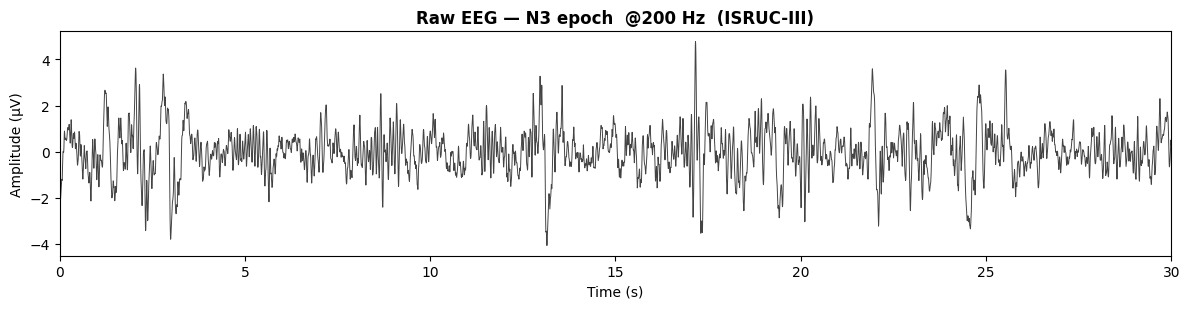

In [6]:
# ── Load local ISRUC-III data (.rec + annotation .txt) ────────────────────
import os, shutil, mne, numpy as np, matplotlib.pyplot as plt
from sleep_quality_model import EEGPreprocessor, SleepDataLoader

DATA_DIR = CONFIG["data_dir"]
CH       = CONFIG["eeg_channel"]
N        = CONFIG["n_subjects"]
SR       = CONFIG["sampling_rate"]   # 200 Hz

# ISRUC-III stage mapping: raw label -> internal (0=W,1=N1,2=N2,3=N3,4=REM)
STAGE_MAP_ISRUC = {
    0: 0,   # Wake
    1: 1,   # N1
    2: 2,   # N2
    3: 3,   # N3 (SWS)
    4: 3,   # N4 -> N3 (old AASM)
    5: 4,   # REM
    6: -1,  # Movement / artifact -> discard
    9: -1,  # Unknown -> discard
}

def find_rec_files_isruc(data_dir, n_subjects):
    """Find .rec files using os.listdir to avoid glob spaces-in-path bug.
    Supports both flat layout (data_dir/N.rec) and
    subfolder layout (data_dir/N/N.rec)."""
    rec_files = []
    for subj_id in range(1, n_subjects + 1):
        # Try subfolder layout first: data_dir/1/1.rec
        subj_folder = os.path.join(data_dir, str(subj_id))
        found = False
        if os.path.isdir(subj_folder):
            for fname in os.listdir(subj_folder):
                if fname.lower().endswith(".rec"):
                    rec_files.append(os.path.join(subj_folder, fname))
                    found = True
                    break
        if not found:
            # Try flat layout: data_dir/1.rec or data_dir/SN001.rec
            for fname in os.listdir(data_dir):
                if fname.lower().endswith(".rec") and (
                    fname.startswith(str(subj_id)) or
                    fname.upper().startswith(f"SN{subj_id:03d}")
                ):
                    rec_files.append(os.path.join(data_dir, fname))
                    break
    return sorted(rec_files)

def parse_isruc_txt(txt_path):
    """Read ISRUC-III text annotation (one integer per line)."""
    stages = []
    with open(txt_path, 'r') as f:
        for line in f:
            line = line.strip()
            if not line or not line[0].isdigit():
                continue
            try:
                raw_stage = int(line.split()[0])
                stages.append(STAGE_MAP_ISRUC.get(raw_stage, -1))
            except ValueError:
                continue
    return np.array(stages, dtype=np.int64)

def load_isruc_annotations(name, subj_dir):
    """Load annotation from subj_dir. Try _1.txt first."""
    txt = os.path.join(subj_dir, f"{name}_1.txt")
    if os.path.exists(txt):
        labels = parse_isruc_txt(txt)
        if len(labels) > 0:
            return labels, 'txt'
    return None, None

# ── Main loading loop ──────────────────────────────────────────────────────
rec_paths = find_rec_files_isruc(DATA_DIR, N)
pre = EEGPreprocessor(sampling_rate=SR, epoch_duration=30)
all_eeg, all_delta, all_stage, all_quality = [], [], [], []
night_ids = []

print(f"Found {len(rec_paths)} .rec files. Loading...\n")
for rec_path in rec_paths:
    name     = os.path.splitext(os.path.basename(rec_path))[0]   # "1", "2", ...
    subj_dir = os.path.dirname(rec_path)
    sid      = int(name.replace("SN", "").lstrip("0") or "0")
    print(f"  [Subject {sid}] ", end="", flush=True)

    labels, ann_src = load_isruc_annotations(name, subj_dir)
    if labels is None:
        print("✗ no annotation"); continue

    try:
        # Copy .rec -> /tmp/*.edf to bypass MNE extension check
        tmp_path = f"/tmp/_isruc_{name}.edf"
        if not os.path.exists(tmp_path):
            shutil.copy2(rec_path, tmp_path)

        raw = mne.io.read_raw_edf(tmp_path, preload=True, verbose=False)
        if raw.info['sfreq'] != SR:
            raw.resample(SR, verbose=False)

        # Channel selection
        ch = None
        for candidate in [CH, 'C4-A1', 'F4-A1', 'C3-A2']:
            if candidate in raw.ch_names:
                ch = candidate; break
        if ch is None:
            ch = raw.ch_names[0]
        eeg = raw.get_data(picks=[ch], units='uV')[0].astype(np.float32)

        epochs, deltas, lbls = pre.create_epochs(eeg, labels=labels)

        # Align label count with epoch count
        if len(lbls) > len(epochs):
            lbls = lbls[:len(epochs)]
        elif len(lbls) < len(epochs):
            pad = np.full(len(epochs) - len(lbls), -1, dtype=np.int64)
            lbls = np.concatenate([lbls, pad])

        valid = lbls != -1
        epochs, deltas, lbls = epochs[valid], deltas[valid], lbls[valid]
        if len(epochs) == 0:
            print("no valid epochs"); continue

        quality = SleepDataLoader._delta_to_quality(deltas)
        all_eeg.append(epochs)
        all_delta.append(deltas)
        all_stage.append(lbls)
        all_quality.append(quality)
        night_ids.extend([sid] * len(epochs))
        print(f"✓ {len(epochs)} epochs  (ch={ch}, ann={ann_src})")

    except Exception as e:
        print(f"✗ {e}")

if not all_eeg:
    raise RuntimeError("No data loaded! Check DATA_DIR: " + DATA_DIR)

raw_eegs       = np.concatenate(all_eeg).astype(np.float32)
delta_powers   = np.concatenate(all_delta).reshape(-1, 1).astype(np.float32)
stage_labels   = np.concatenate(all_stage).astype(np.int64)
quality_labels = np.concatenate(all_quality).astype(np.float32)
night_ids      = np.array(night_ids)

print(f"\n── Dataset loaded ───────────────────────────────────────")
print(f"  Total epochs : {raw_eegs.shape[0]:,}")
print(f"  Signal shape : {raw_eegs.shape}")
print(f"  Subjects     : {len(np.unique(night_ids))}")
print(f"  Stage distribution:")
unique, counts = np.unique(stage_labels, return_counts=True)
for u, c in zip(unique, counts):
    pct = c / len(stage_labels) * 100
    print(f"    {STAGE_MAP[u]:>5}: {c:5d} ({pct:.1f}%)")

# Plot a sample N3 epoch
ex_idx = np.where(stage_labels == 3)[0][0] if (stage_labels == 3).any() else 0
example = raw_eegs[ex_idx]
t = np.arange(len(example)) / SR
fig, ax = plt.subplots(figsize=(12, 3.2))
ax.plot(t, example, color='#444', lw=0.7)
ax.set_title(f'Raw EEG — {STAGE_MAP[stage_labels[ex_idx]]} epoch  @{SR} Hz  (ISRUC-III)', fontweight='bold')
ax.set_xlabel('Time (s)'); ax.set_ylabel('Amplitude (μV)'); ax.set_xlim(0, 30)
plt.tight_layout(); plt.show()


## 3. Step 2 — Preprocessing, one transformation at a time

The preprocessing block has three sub-steps. We show the **before vs after** of each so you can see
exactly what it does.

### 3.1 Band-pass filter (0.5-40 Hz)

**What is happening:** A 4th-order Butterworth band-pass keeps only frequencies between 0.5 and 40 Hz.

**Why:** Below 0.5 Hz is mostly slow electrode drift / sweat artifacts; above ~40 Hz is muscle
activity and electrical noise - neither helps sleep staging, so we drop both.

**What to look for:** the bottom (filtered) trace is cleaner and more centered than the top (raw)
trace, but the overall wave shape is preserved.

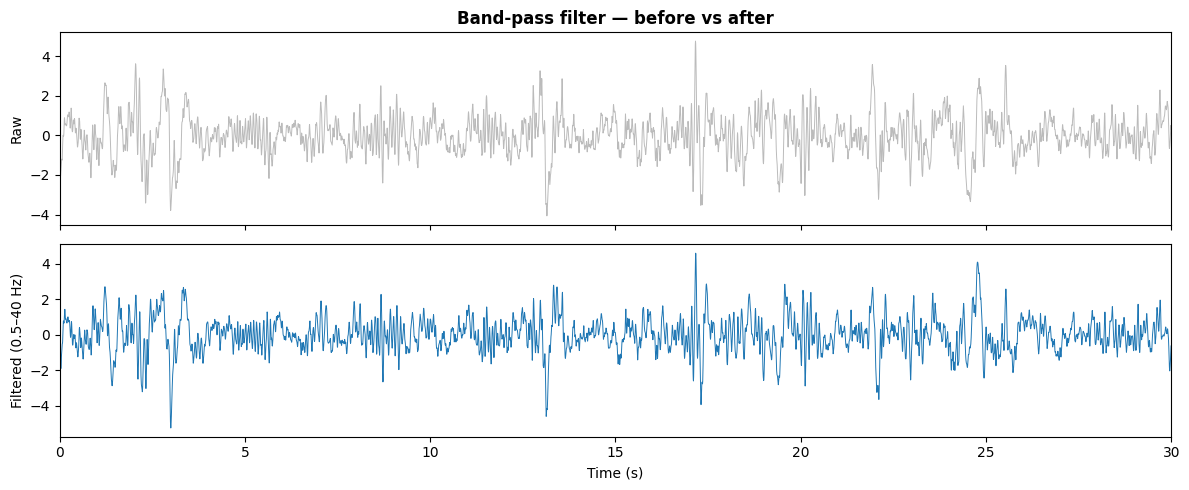

raw std=1.00  ->  filtered std=0.99


In [7]:
filtered = pre.bandpass_filter(example)

fig, axes = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
axes[0].plot(t, example, color='#bbb', lw=0.7); axes[0].set_ylabel('Raw'); axes[0].set_title('Band-pass filter — before vs after', fontweight='bold')
axes[1].plot(t, filtered, color='#1f77b4', lw=0.7); axes[1].set_ylabel('Filtered (0.5–40 Hz)')
axes[1].set_xlabel('Time (s)'); axes[1].set_xlim(0, 30)
plt.tight_layout(); plt.show()
print(f"raw std={example.std():.2f}  ->  filtered std={filtered.std():.2f}")

### 3.2 Normalize (z-score)

**What is happening:** Rescale the epoch to **mean 0, std 1** (`(x - mean) / std`).

**Why:** absolute EEG amplitude varies by person, electrode, and night. Z-scoring makes every epoch
comparable so the network learns physiology, not the recording setup.

**What to look for:** identical wave shape, but the y-axis is now in standard-deviation units; printed
mean ~ 0 and std ~ 1.

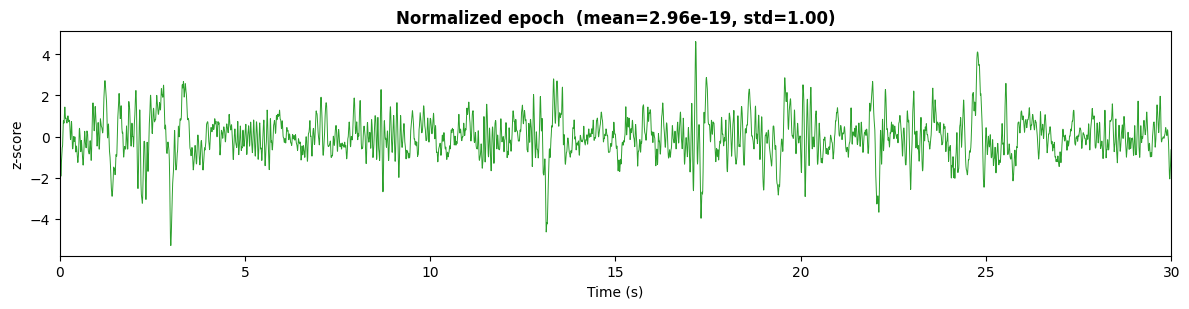

In [8]:
norm = pre.normalize_epoch(filtered)

fig, ax = plt.subplots(figsize=(12, 3.2))
ax.plot(t, norm, color='#2ca02c', lw=0.7)
ax.set_title(f'Normalized epoch  (mean={norm.mean():.2e}, std={norm.std():.2f})', fontweight='bold')
ax.set_xlabel('Time (s)'); ax.set_ylabel('z-score'); ax.set_xlim(0, 30)
plt.tight_layout(); plt.show()

### 3.3 Extract delta power (0.5-4 Hz)

**What is happening:** isolate the **delta band (0.5-4 Hz)** and compute its **power** = mean of the
squared signal (one number per epoch).

**Why:** delta is the signature of deep N3 sleep. High delta power -> more deep sleep -> higher quality.
This number becomes the **handcrafted feature** fused into the network, injecting domain knowledge.

**What to look for:** the red "delta only" trace is a smooth slow wave (fast wiggles gone); the boxed
delta-power value is high for this N3 epoch. The printout shows all five band powers - delta should lead.

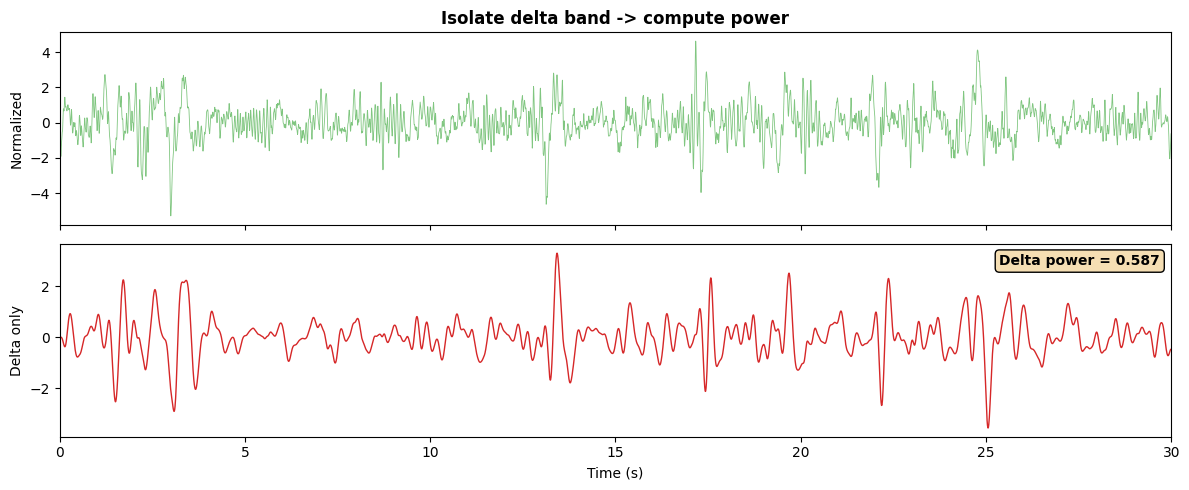

Band powers: {'delta': 0.587, 'theta': 0.162, 'alpha': 0.164, 'sigma': 0.061, 'beta': 0.026}


In [9]:
sos_delta = butter(4, [0.5, 4], btype='band', fs=SR, output='sos')
delta_sig = sosfilt(sos_delta, norm)
power = float(np.mean(delta_sig ** 2))

fig, axes = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
axes[0].plot(t, norm, color='#2ca02c', lw=0.6, alpha=0.6); axes[0].set_ylabel('Normalized'); axes[0].set_title('Isolate delta band -> compute power', fontweight='bold')
axes[1].plot(t, delta_sig, color='#d62728', lw=1); axes[1].set_ylabel('Delta only')
axes[1].set_xlabel('Time (s)'); axes[1].set_xlim(0, 30)
axes[1].text(0.99, 0.95, f'Delta power = {power:.3f}', transform=axes[1].transAxes,
             ha='right', va='top', fontweight='bold', bbox=dict(boxstyle='round', facecolor='wheat'))
plt.tight_layout(); plt.show()

# all five bands for this epoch
bands = pre.extract_frequency_bands(norm)
print("Band powers:", {k: round(v, 3) for k, v in bands.items()})

## 4. Step 3 — Epoching & the full dataset

The steps above happen for **every** 30-s epoch. The dataset now holds all epochs with their delta
power, stage label, and a quality label derived from normalized delta power (per night). When you
pool several nights (`data_source` = `"download"` or `"folder"`), `night_ids` records which recording
each epoch came from — used later for the per-night timeline.

The data source is set once in `CONFIG` (§1); nothing here needs editing to switch datasets.

raw_eegs      : (8889, 6000)
delta_powers  : (8889, 1)
stage_labels  : (8889,)
quality_labels: (8889, 1)
nights pooled : 10


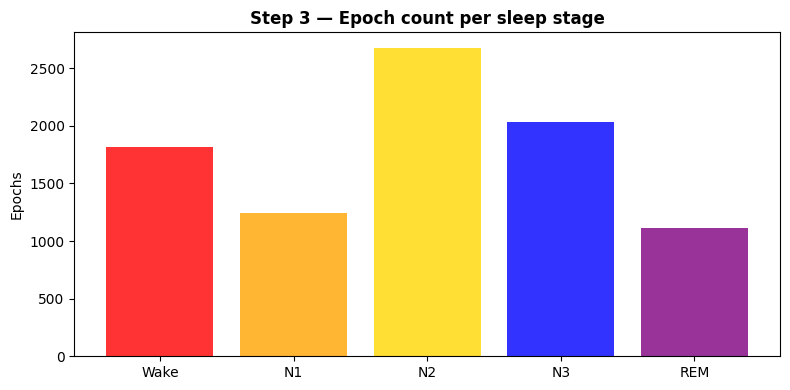

In [13]:
# এই line গুলো আগে থেকেই থাকার কথা ছিল — এখন define করো
STAGE_MAP    = {0:'Wake', 1:'N1', 2:'N2', 3:'N3', 4:'REM'}
STAGE_COLORS = ['red', 'orange', 'gold', 'blue', 'purple']

print("raw_eegs      :", raw_eegs.shape)
print("delta_powers  :", delta_powers.shape)
print("stage_labels  :", stage_labels.shape)
print("quality_labels:", quality_labels.shape)
if night_ids is not None:
    print("nights pooled :", len(np.unique(night_ids)))

stages, counts = np.unique(stage_labels, return_counts=True)
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar([STAGE_MAP[s] for s in stages], counts,
       color=[STAGE_COLORS[s] for s in stages], alpha=0.8)
ax.set_title('Step 3 — Epoch count per sleep stage', fontweight='bold')
ax.set_ylabel('Epochs')
plt.tight_layout()
plt.show()

## 5. Step 4 — Validate the features across all epochs

Before training, sanity-check that the features behave physiologically. The single most important
check: **N3 (deep sleep) should have the highest delta power.** If that holds, the signal pipeline is trustworthy.

| What to look for | ❌ If wrong |
|---|---|
| Boxplot: N3 > others; PSD: delta peak highest | N3 not highest → labels wrong or feature extraction wrong |

/var/folders/fs/csz467_d6lzd3c40xv8w1tg40000gn/T/ipykernel_2567/1814202931.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = axes[0].boxplot(data, labels=[STAGE_MAP[s] for s in range(5)], patch_artist=True)


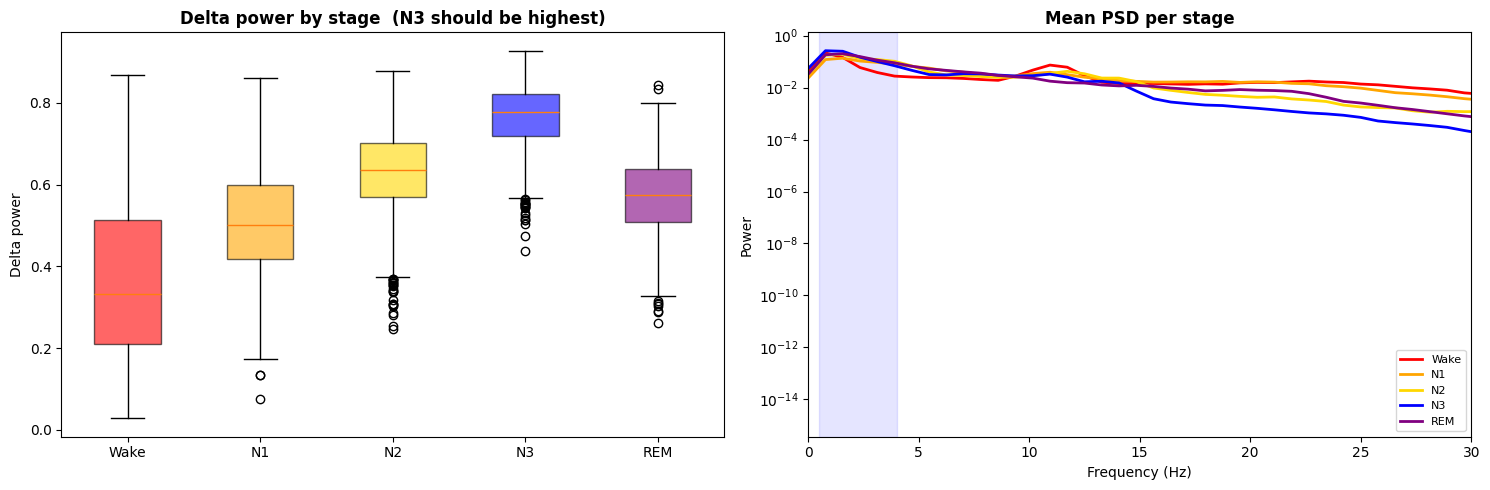

Median delta power per stage: {'Wake': 0.333, 'N1': 0.501, 'N2': 0.635, 'N3': 0.777, 'REM': 0.575}


In [16]:
from scipy.signal import welch
dp = delta_powers.flatten()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# delta power per stage (boxplot)
data = [dp[stage_labels == s] for s in range(5)]
bp = axes[0].boxplot(data, labels=[STAGE_MAP[s] for s in range(5)], patch_artist=True)
for patch, c in zip(bp['boxes'], STAGE_COLORS):
    patch.set_facecolor(c); patch.set_alpha(0.6)
axes[0].set_title('Delta power by stage  (N3 should be highest)', fontweight='bold')
axes[0].set_ylabel('Delta power')

# mean PSD per stage
for s in range(5):
    idx = np.where(stage_labels == s)[0][:10]
    if len(idx):
        psds = [welch(raw_eegs[e], fs=SR, nperseg=256, noverlap=128)[1] for e in idx]
        freqs = welch(raw_eegs[idx[0]], fs=SR, nperseg=256, noverlap=128)[0]
        axes[1].semilogy(freqs, np.mean(psds, axis=0), color=STAGE_COLORS[s], lw=2, label=STAGE_MAP[s])
axes[1].axvspan(0.5, 4, alpha=0.1, color='blue')
axes[1].set_xlim(0, 30); axes[1].set_title('Mean PSD per stage', fontweight='bold')
axes[1].set_xlabel('Frequency (Hz)'); axes[1].set_ylabel('Power'); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

print("Median delta power per stage:",
      {STAGE_MAP[s]: round(float(np.median(dp[stage_labels==s])), 3) for s in range(5)})

### 5b. Delta power across the night (timeline)

**What is happening:** delta power for **every epoch in chronological order**, sleep onset (left) to
morning (right), colored by stage. When several nights are pooled, each night is normalized to its own
0-1 time axis and overlaid so they line up.

**Why:** healthy sleep front-loads deep sleep - most N3 (highest delta) is in the **first half** of the
night, tapering as REM rises. A strong end-to-end check that signal processing *and* epoch ordering are correct.

| What to look for | If wrong |
|---|---|
| High delta early, lower delta late | Flat / reversed -> suspicious data or shuffled epochs |

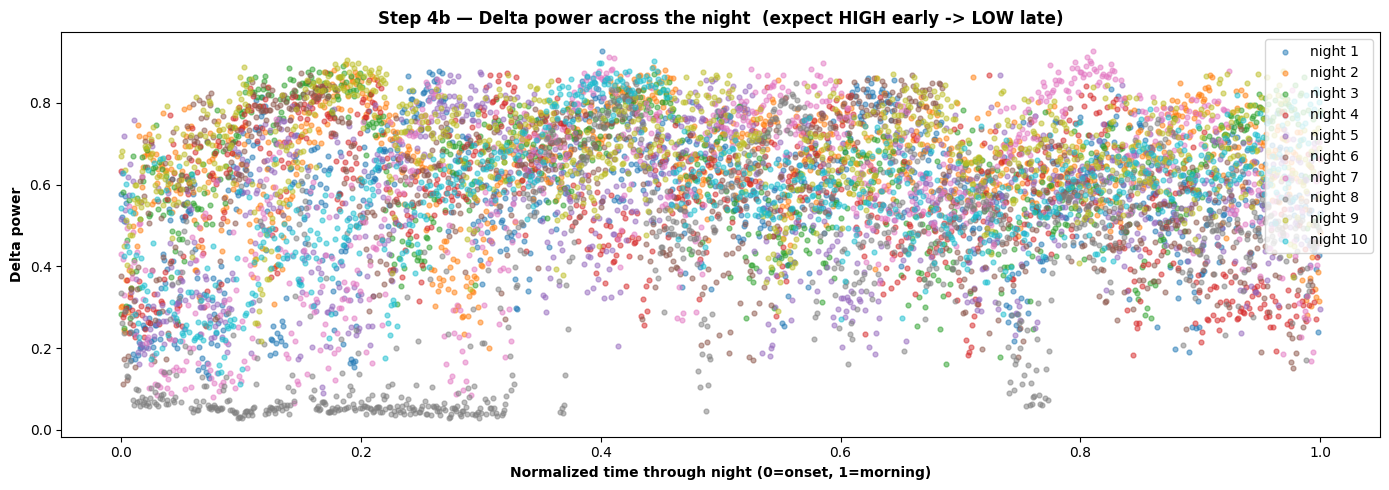

Mean delta power - first half: 0.572  |  second half: 0.592
Note: early <= late - expected for pooled/real data with little deep sleep.


In [17]:
fig, ax = plt.subplots(figsize=(14, 5))

if night_ids is not None and len(np.unique(night_ids)) > 1:
    # pooled: overlay each night on a normalized 0-1 time axis
    for nid in np.unique(night_ids):
        m = night_ids == nid
        d = delta_powers.flatten()[m]
        x = np.linspace(0, 1, len(d))
        ax.scatter(x, d, s=12, alpha=0.5, label=f'night {nid}')
    ax.set_xlabel('Normalized time through night (0=onset, 1=morning)', fontweight='bold')
    # average trend across nights
    ax.legend(fontsize=8, ncol=min(6, len(np.unique(night_ids))))
    first_vals, second_vals = [], []
    for nid in np.unique(night_ids):
        d = delta_powers.flatten()[night_ids == nid]
        h = len(d)//2
        first_vals.append(d[:h].mean()); second_vals.append(d[h:].mean())
    fh, sh = np.mean(first_vals), np.mean(second_vals)
else:
    dp = delta_powers.flatten()
    epochs = np.arange(len(dp)); mid = len(dp)//2
    sc = ax.scatter(epochs, dp, c=stage_labels, cmap='RdYlBu_r', s=35, alpha=0.8)
    ax.axvline(mid, color='black', ls='--', lw=2, alpha=0.6, label='night midpoint')
    ax.axvspan(0, mid, color='green', alpha=0.07)
    ax.axvspan(mid, len(dp), color='red', alpha=0.07)
    z = np.polyfit(epochs, dp, 1)
    ax.plot(epochs, np.poly1d(z)(epochs), 'k-', lw=2, alpha=0.7, label='trend')
    cb = plt.colorbar(sc, ax=ax); cb.set_label('Stage (0=W .. 4=REM)', fontweight='bold')
    ax.set_xlabel('Epoch (chronological, 30-s each)', fontweight='bold')
    fh, sh = dp[:mid].mean(), dp[mid:].mean()

ax.set_ylabel('Delta power', fontweight='bold')
ax.set_title('Step 4b — Delta power across the night  (expect HIGH early -> LOW late)', fontweight='bold')
ax.legend(loc='upper right')
plt.tight_layout(); plt.show()

print(f"Mean delta power - first half: {fh:.3f}  |  second half: {sh:.3f}")
print("Pattern OK (early > late)." if fh > sh else
      "Note: early <= late - expected for pooled/real data with little deep sleep.")

## 6. Step 5 — Build the model and inspect one forward pass

**What is happening:** instantiate `SleepQualityNet` and push one small batch through it.

**The architecture (matches the diagram):**
1. **1D-CNN** extracts local temporal patterns from the raw epoch.
2. **BiLSTM** models how those patterns evolve through the epoch.
3. **Attention** weights the most informative parts.
4. **Fusion** concatenates the learned features with the handcrafted **delta power**.
5. A shared layer feeds **three heads**: stage classifier (5 classes), N3-quality regressor (0-1),
   and a physiological-constraint head.

**What to look for:** three output shapes - `stage_logits (B,5)`, `quality (B,1)`, `phys (B,1)` - and
a sensible parameter count.

In [20]:
model = SleepQualityNet(input_length=SR*30, num_stages=5)
n_params = sum(p.numel() for p in model.parameters())
print(f"SleepQualityNet — {n_params:,} parameters")
print(f"Input length: {SR}×30 = {SR*30} samples (ISRUC-III @ {SR} Hz)")

xb = torch.FloatTensor(raw_eegs[:4]).unsqueeze(1)
db = torch.FloatTensor(delta_powers[:4])
with torch.no_grad():
    s_logits, q_pred, phys = model(xb, db)
print("stage_logits:", tuple(s_logits.shape), "| quality:", tuple(q_pred.shape), "| phys:", tuple(phys.shape))


SleepQualityNet — 922,376 parameters
Input length: 200×30 = 6000 samples (ISRUC-III @ 200 Hz)
stage_logits: (4, 5) | quality: (4, 1) | phys: (4, 1)


## 7. Step 6 — Train, and watch the loss/accuracy come down/up

The trainer optimizes `L_total = λ₁·L_cls + λ₂·L_qual + λ₃·L_phys`. We plot the **training history it
produced** — loss should fall, accuracy should rise.

| What to look for | ❌ If wrong |
|---|---|
| Loss decreasing; accuracy increasing | Loss flat/zigzag → LR too high; acc flat → model not learning |

**Proposed contributions — where they live in the code:**

| # | Contribution | Implemented by |
|---|---|---|
| 1 | Dual-output: stage classification + N3 quality score (0–100) | `SleepQualityNet.stage_head` + `quality_head` |
| 2 | Physiologically-informed delta-power fusion | `torch.cat([attended, delta_power])` in `fusion` |
| 3 | **N3-aware weighted loss** (higher weight to N3) | `MultiTaskLoss(n3_weight=...)` — set in `CONFIG["n3_loss_weight"]` |
| 4 | Multi-task physiological loss (cls + qual + phys) | `MultiTaskLoss.forward` → `L_cls + L_qual + L_phys` |


N3 class loss weight = 2.0  (weights=[1.0, 1.0, 1.0, 2.0, 1.0])
  train_loss=0.6286  val_loss=0.8782  acc=0.616  f1=0.575  rmse=0.100  r2=0.824
  train_loss=0.4275  val_loss=1.8817  acc=0.422  f1=0.353  rmse=0.125  r2=0.724
  train_loss=0.3727  val_loss=1.1534  acc=0.525  f1=0.465  rmse=0.074  r2=0.903
  train_loss=0.3451  val_loss=0.6965  acc=0.596  f1=0.530  rmse=0.074  r2=0.902
  train_loss=0.3118  val_loss=0.9542  acc=0.571  f1=0.547  rmse=0.064  r2=0.928
  train_loss=0.2917  val_loss=0.7105  acc=0.617  f1=0.600  rmse=0.066  r2=0.923
  train_loss=0.2979  val_loss=0.5402  acc=0.714  f1=0.711  rmse=0.078  r2=0.894
  train_loss=0.2739  val_loss=1.3690  acc=0.545  f1=0.447  rmse=0.078  r2=0.894
  train_loss=0.2634  val_loss=0.5591  acc=0.719  f1=0.721  rmse=0.082  r2=0.883
  train_loss=0.2472  val_loss=1.9372  acc=0.544  f1=0.481  rmse=0.073  r2=0.907


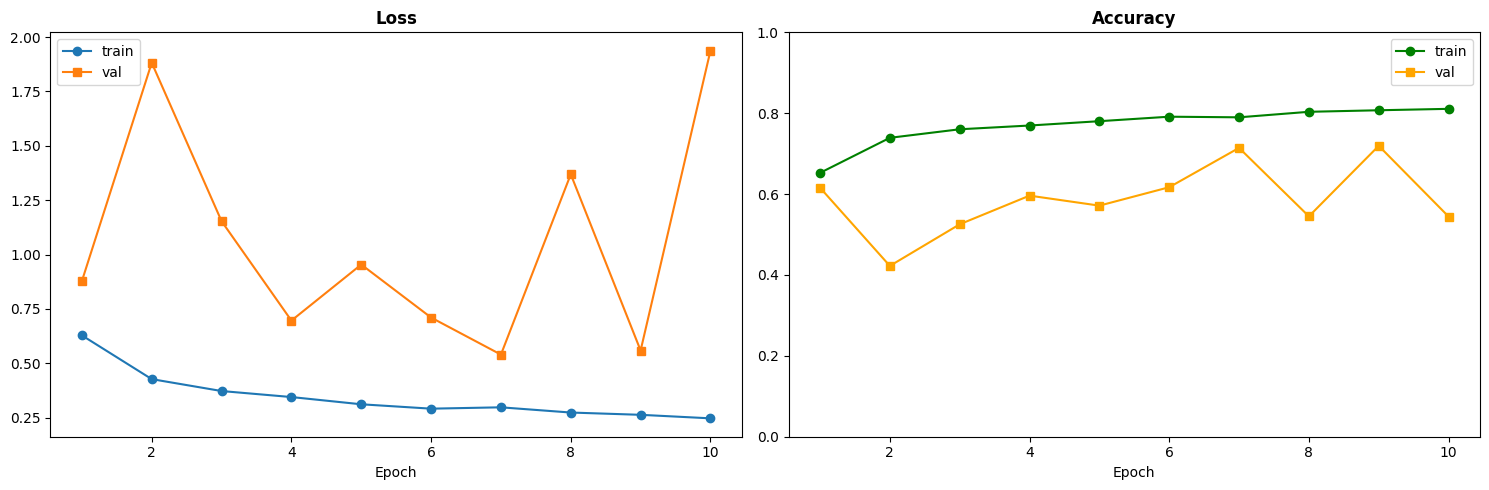

In [22]:
split = int(0.8 * len(raw_eegs))
train_ds = SleepDataLoader.numpy_to_tensor_dataset(
    raw_eegs[:split], delta_powers[:split], stage_labels[:split], quality_labels[:split])
val_ds = SleepDataLoader.numpy_to_tensor_dataset(
    raw_eegs[split:], delta_powers[split:], stage_labels[split:], quality_labels[split:])
train_loader = torch.utils.data.DataLoader(train_ds, batch_size=CONFIG["batch_size"], shuffle=True, drop_last=True)
val_loader = torch.utils.data.DataLoader(val_ds, batch_size=CONFIG["batch_size"], shuffle=False)

model = SleepQualityNet(input_length=SR*30, num_stages=5)
# N3-aware weighted loss (contribution #3): upweight the N3 class.
trainer = SleepQualityTrainer(model,  checkpoint_path='best_model.pth',
                              n3_loss_weight=CONFIG["n3_loss_weight"])
print(f"N3 class loss weight = {CONFIG['n3_loss_weight']}  (weights={trainer.criterion.class_weights.tolist()})")
trainer.train(train_loader, val_loader, epochs=CONFIG["epochs"], verbose=False)

# plot the history the trainer recorded
ep = np.arange(1, len(trainer.train_losses)+1)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].plot(ep, trainer.train_losses, 'o-', label='train'); axes[0].plot(ep, trainer.val_losses, 's-', label='val')
axes[0].set_title('Loss', fontweight='bold'); axes[0].set_xlabel('Epoch'); axes[0].legend()
axes[1].plot(ep, trainer.train_accs, 'o-', color='green', label='train'); axes[1].plot(ep, trainer.val_accs, 's-', color='orange', label='val')
axes[1].set_title('Accuracy', fontweight='bold'); axes[1].set_xlabel('Epoch'); axes[1].set_ylim(0,1); axes[1].legend()
plt.tight_layout(); plt.show()

## 8. Step 7 — Evaluate the trained model

Collect predictions on the validation set and show the two task outputs: a **confusion matrix**
(stage classification) and a **predicted-vs-true** scatter (quality regression).

| What to look for | ❌ If wrong |
|---|---|
| Confusion matrix diagonal bright; quality points near diagonal | Off-diagonal heavy → class imbalance; scattered points → regression failing |

> **Reading the confusion matrix honestly.** A *perfect* diagonal (100% accuracy) is a **red flag**,
> not a success — on real EEG even expert human scorers agree only ~83%, and some N1↔N2 / N2↔N3
> confusion is expected. A flawless matrix usually means the data is too easy (synthetic with
> `realism=0`), or there is data leakage. With `CONFIG["synthetic_realism"]=0.4` you should see
> believable confusion here; on real Sleep-EDF, target roughly 85–92% accuracy.


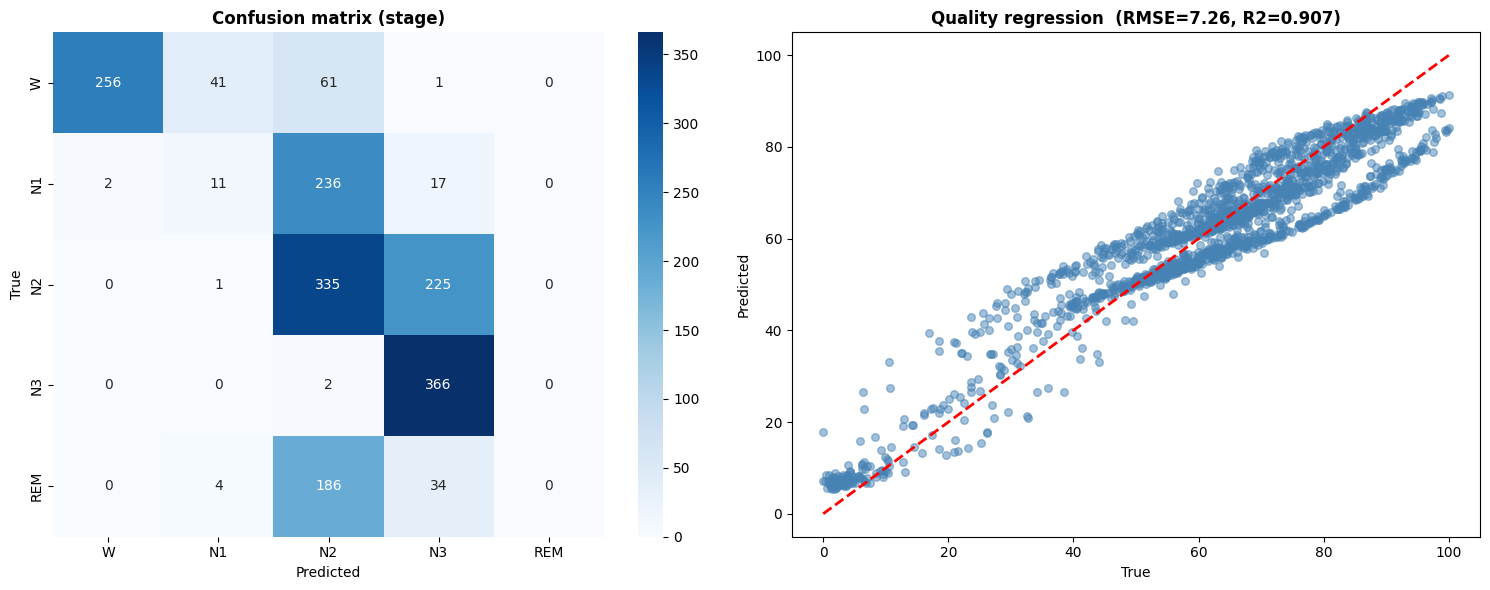

In [24]:
import seaborn as sns
from sklearn.metrics import confusion_matrix

model.eval()
yt_s, yp_s, yt_q, yp_q = [], [], [], []
with torch.no_grad():
    for raw_eeg, delta, s_lab, q_lab in val_loader:
        logits, q_pred, _ = model(raw_eeg, delta)
        yp_s.extend(torch.argmax(logits,1).cpu().numpy()); yt_s.extend(s_lab.numpy())
        yp_q.extend(q_pred.cpu().numpy().flatten()*100);   yt_q.extend(q_lab.numpy().flatten()*100)
yt_s, yp_s = np.array(yt_s), np.array(yp_s)
yt_q, yp_q = np.array(yt_q), np.array(yp_q)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
cm = confusion_matrix(yt_s, yp_s, labels=list(range(5)))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['W','N1','N2','N3','REM'], yticklabels=['W','N1','N2','N3','REM'])
axes[0].set_title('Confusion matrix (stage)', fontweight='bold'); axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('True')

axes[1].scatter(yt_q, yp_q, alpha=0.5, s=30, color='steelblue')
lo, hi = min(yt_q.min(), yp_q.min()), max(yt_q.max(), yp_q.max())
axes[1].plot([lo,hi],[lo,hi],'r--', lw=2)
rmse = float(np.sqrt(np.mean((yt_q-yp_q)**2)))
denom = np.sum((yt_q-yt_q.mean())**2); r2 = 1 - np.sum((yt_q-yp_q)**2)/denom if denom>0 else 0
axes[1].set_title(f'Quality regression  (RMSE={rmse:.2f}, R2={r2:.3f})', fontweight='bold')
axes[1].set_xlabel('True'); axes[1].set_ylabel('Predicted')
plt.tight_layout(); plt.show()

## 9. Step 8 — Explainability: which band drives each stage?

Mean band power per stage, computed from the data. Delta should dominate for N3 — confirming the
model's most informative feature is physiologically sensible.

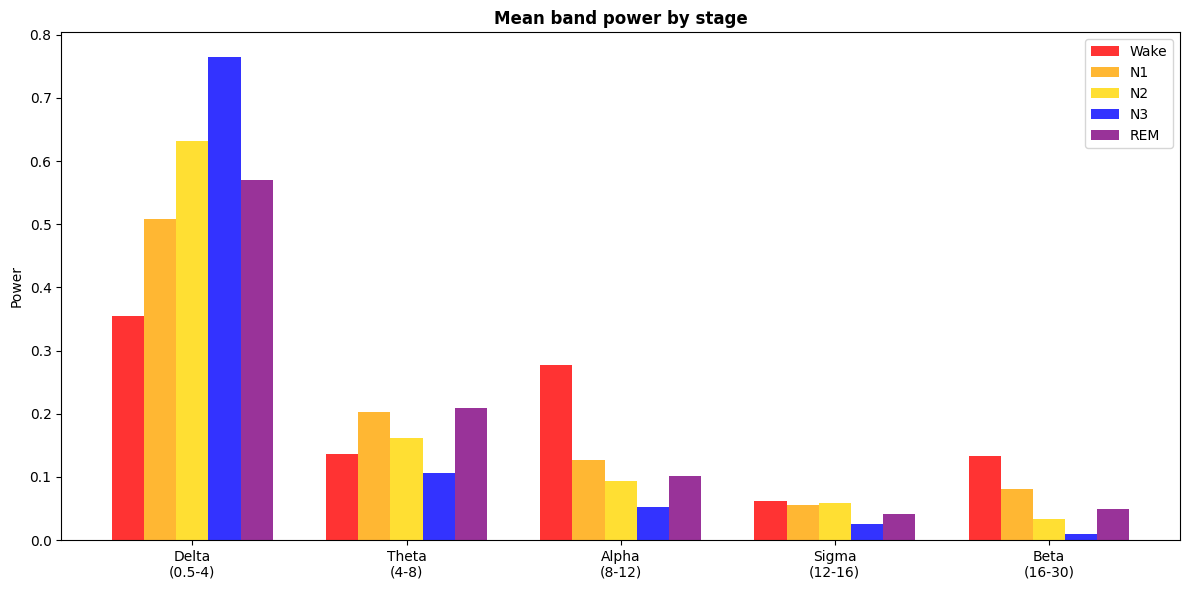

In [25]:
band_keys = ['delta','theta','alpha','sigma','beta']
band_names = ['Delta\n(0.5-4)','Theta\n(4-8)','Alpha\n(8-12)','Sigma\n(12-16)','Beta\n(16-30)']
powers = np.array([[pre.extract_frequency_bands(e)[k] for k in band_keys] for e in raw_eegs])

fig, ax = plt.subplots(figsize=(12, 6))
x = np.arange(len(band_names)); w = 0.15
for s in range(5):
    mask = stage_labels == s
    if mask.sum():
        ax.bar(x + w*s, powers[mask].mean(axis=0), w, label=STAGE_MAP[s], color=STAGE_COLORS[s], alpha=0.8)
ax.set_xticks(x + w*2); ax.set_xticklabels(band_names)
ax.set_title('Mean band power by stage', fontweight='bold'); ax.set_ylabel('Power'); ax.legend()
plt.tight_layout(); plt.show()

### 9b. Feature importance — which band matters most?

**What is happening:** summarize how strongly each frequency band separates the sleep stages into a
single **importance score per band** (between-stage variance of mean power, normalized to sum to 1), then rank.

**Why:** the headline interpretability check. The model fuses delta power explicitly because delta
should be most discriminative for deep sleep - this confirms that holds in your data.

| What to look for | If wrong |
|---|---|
| Delta ranked highest | Beta/alpha highest -> wrong features or noisy signal |

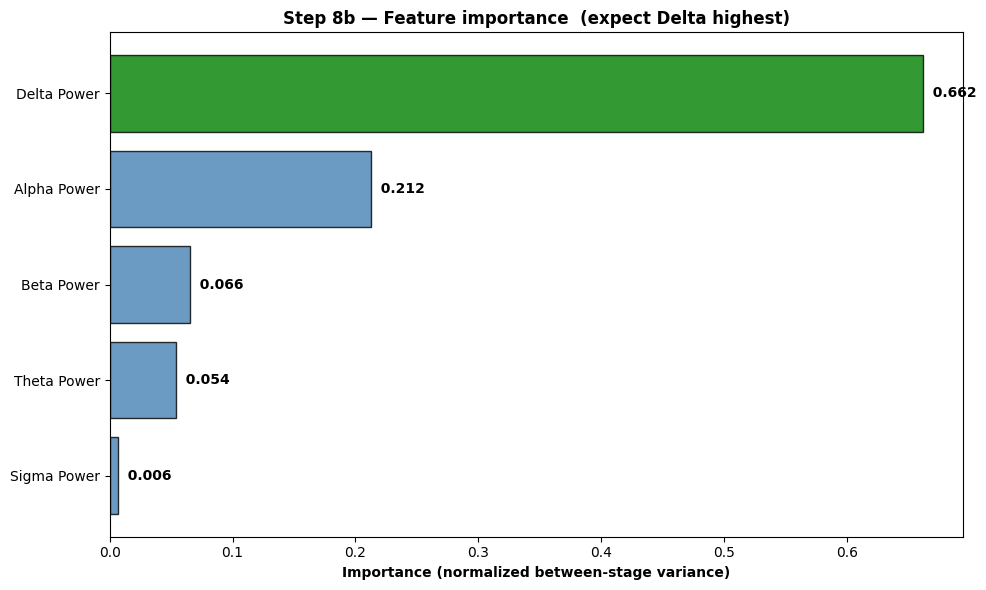

Ranking: {'Delta Power': 0.662, 'Alpha Power': 0.212, 'Beta Power': 0.066, 'Theta Power': 0.054, 'Sigma Power': 0.006}


In [26]:
band_keys = ['delta','theta','alpha','sigma','beta']
band_disp = ['Delta Power','Theta Power','Alpha Power','Sigma Power','Beta Power']
powers = np.array([[pre.extract_frequency_bands(e)[k] for k in band_keys] for e in raw_eegs])

stage_means = np.array([powers[stage_labels == s].mean(axis=0)
                        for s in range(5) if (stage_labels == s).any()])
importance = stage_means.var(axis=0); importance = importance / importance.sum()

order = np.argsort(importance)[::-1]
names = [band_disp[i] for i in order]; scores = importance[order]
colors = ['green' if n == 'Delta Power' else 'steelblue' for n in names]

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(names, scores, color=colors, alpha=0.8, edgecolor='black'); ax.invert_yaxis()
for i, sc in enumerate(scores):
    ax.text(sc, i, f'  {sc:.3f}', va='center', fontweight='bold')
ax.set_xlabel('Importance (normalized between-stage variance)', fontweight='bold')
ax.set_title('Step 8b — Feature importance  (expect Delta highest)', fontweight='bold')
plt.tight_layout(); plt.show()
print("Ranking:", {n: round(float(s), 3) for n, s in zip(names, scores)})

## 10. Step 9 — Inference on a single epoch

**What is happening:** the end-to-end payoff - load the best checkpoint, feed **one** epoch, read off
the predicted stage + quality score.

**Why:** this is exactly how the model is used on a new recording: one epoch in, a stage label +
0-100 quality score out.

**What to look for:** predicted stage (with confidence %) and quality score, printed beside the **true**
stage so you can see whether it matched.

In [30]:
infer = SleepQualityNet(input_length=SR*30, num_stages=5)
infer.load_state_dict(torch.load('best_model.pth'))
infer.eval()

i = split  # first validation epoch
xe = torch.FloatTensor(raw_eegs[i:i+1]).unsqueeze(1)
de = torch.FloatTensor(delta_powers[i:i+1])
with torch.no_grad():
    logits, quality, _ = infer(xe, de)

pred = int(torch.argmax(logits,1).item())
conf = torch.softmax(logits,1).max().item()*100
print("Prediction for one epoch")
print(f"  Predicted stage : {STAGE_MAP[pred]}  ({conf:.1f}% confidence)")
print(f"  Quality score   : {quality.item()*100:.1f} / 100")
print(f"  True stage       : {STAGE_MAP[int(stage_labels[i])]}")

Prediction for one epoch
  Predicted stage : Wake  (99.8% confidence)
  Quality score   : 8.3 / 100
  True stage       : Wake


## 11. XAI — Attention Weight Visualization (RQ2)

**What is happening:** The BiLSTM attention layer assigns a weight to each CNN feature.
Here we extract those weights and visualize them alongside the raw EEG signal.

**What to look for:**
- High attention on delta-rich segments → confirms model focuses on physiologically relevant features
- N3 epochs should show highest attention on slow-wave portions

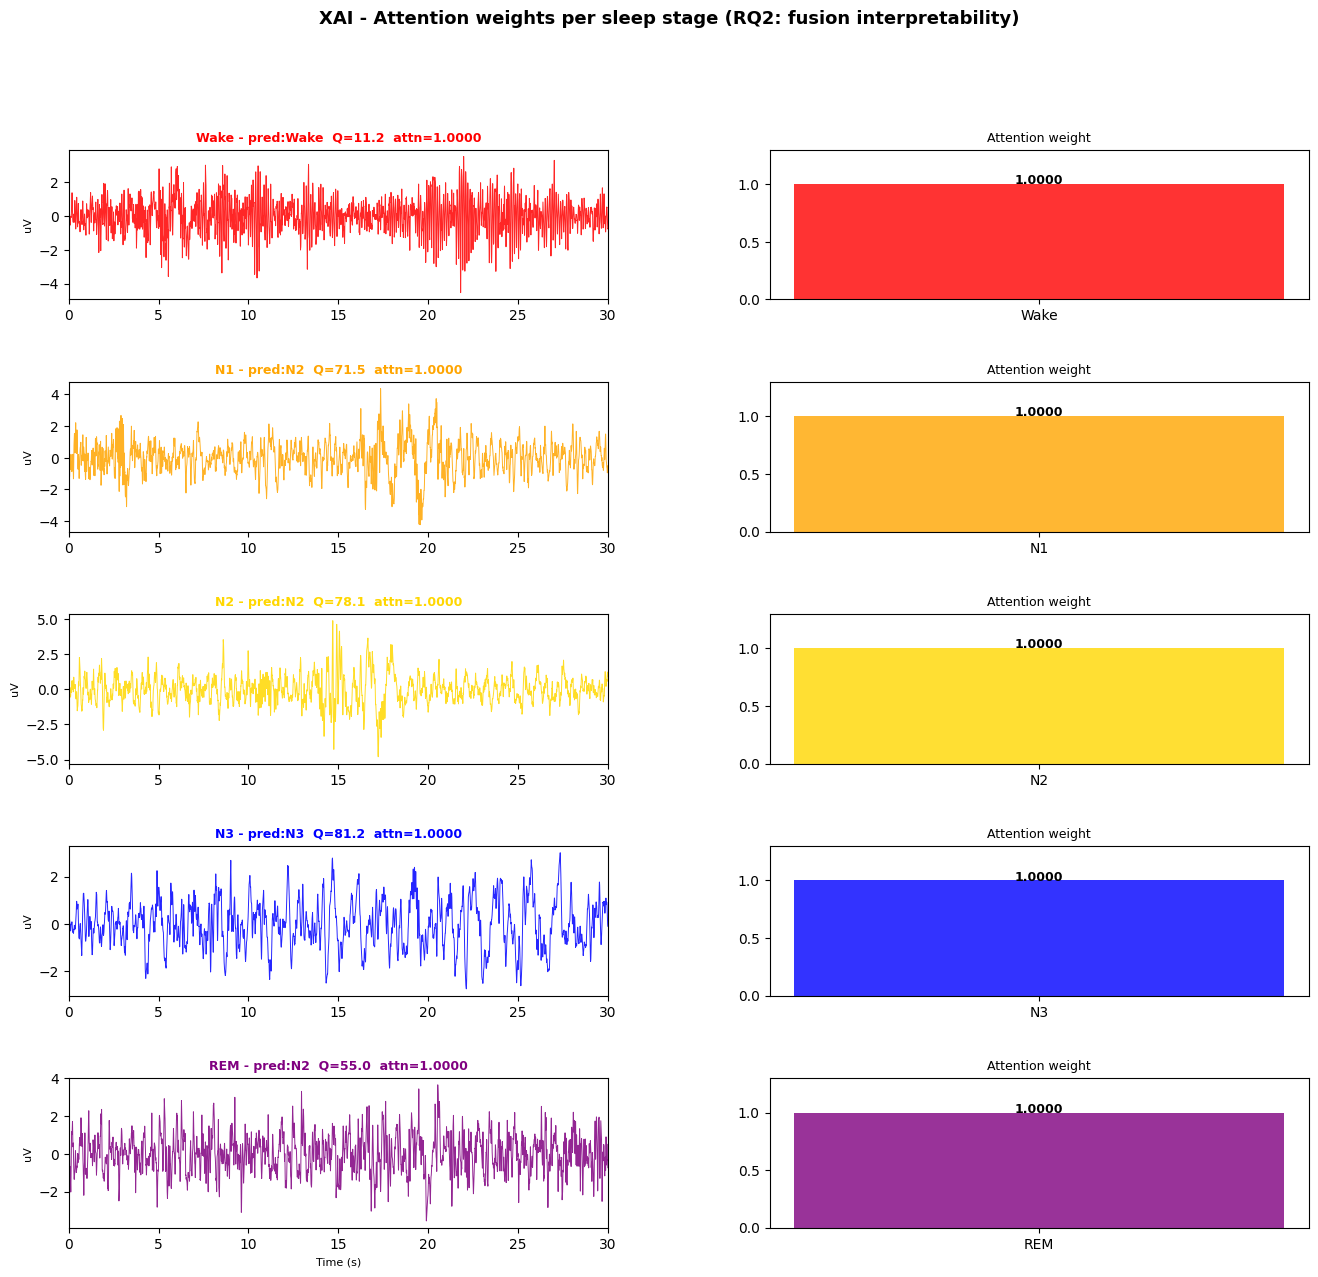

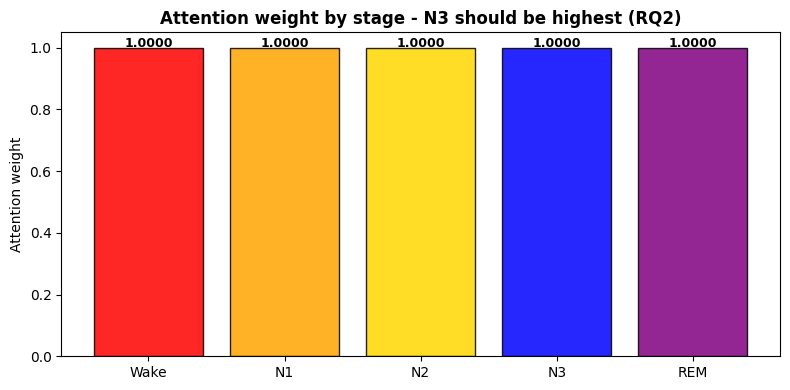

N3 attention: 1.0000
Max attention stage: Wake
N3 has highest attention - confirms physiological relevance (RQ2)


In [33]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

class AttentionExtractor(torch.nn.Module):
    """Wrap model to also return attention weights."""
    def __init__(self, model):
        super().__init__()
        self.model = model

    def forward(self, raw_eeg, delta_power):
        x = self.model.conv1(raw_eeg)
        x = self.model.conv2(x)
        x = self.model.conv3(x)
        cnn_features = x.squeeze(-1)
        lstm_out, _  = self.model.lstm(cnn_features.unsqueeze(1))
        attn_w       = self.model.attention(lstm_out)
        attended     = (lstm_out * attn_w).squeeze(1)
        fused        = self.model.fusion(
            torch.cat([attended, delta_power], dim=1))
        shared       = self.model.shared_fc(fused)
        stage_logits = self.model.stage_head(shared)
        quality      = self.model.quality_head(shared)
        return stage_logits, quality, attn_w.squeeze(-1).squeeze(-1)

extractor = AttentionExtractor(model)
extractor.eval()

stage_names = ['Wake', 'N1', 'N2', 'N3', 'REM']
fig = plt.figure(figsize=(16, 14))
gs  = gridspec.GridSpec(5, 2, figure=fig, hspace=0.55, wspace=0.3)

val_raw    = raw_eegs[split:]
val_stages = stage_labels[split:]
val_delta  = delta_powers[split:]

attn_by_stage = {}

for row, (s_idx, sname) in enumerate(zip(range(5), stage_names)):
    mask  = np.where(val_stages == s_idx)[0]
    if len(mask) == 0:
        continue
    pick  = mask[len(mask)//2]

    eeg_np    = val_raw[pick]
    delta_np  = val_delta[pick]
    t         = np.arange(len(eeg_np)) / SR

    x_t  = torch.FloatTensor(eeg_np).unsqueeze(0).unsqueeze(0)
    d_t  = torch.FloatTensor(delta_np).unsqueeze(0)

    with torch.no_grad():
        logits, quality, attn = extractor(x_t, d_t)

    attn_val  = float(attn.cpu())
    pred_s    = int(torch.argmax(logits, 1).cpu())
    qual_val  = float(quality.cpu()) * 100
    attn_by_stage[sname] = attn_val

    ax_eeg = fig.add_subplot(gs[row, 0])
    ax_eeg.plot(t, eeg_np, color=STAGE_COLORS[s_idx], lw=0.7, alpha=0.85)
    ax_eeg.set_xlim(0, 30)
    ax_eeg.set_title(
        f"{sname} - pred:{stage_names[pred_s]}  Q={qual_val:.1f}  attn={attn_val:.4f}",
        fontsize=9, fontweight='bold', color=STAGE_COLORS[s_idx])
    ax_eeg.set_ylabel('uV', fontsize=8)
    if row == 4: ax_eeg.set_xlabel('Time (s)', fontsize=8)

    ax_a = fig.add_subplot(gs[row, 1])
    bar  = ax_a.bar([sname], [attn_val],
                    color=STAGE_COLORS[s_idx], alpha=0.8, width=0.4)
    ax_a.set_ylim(0, max(attn_by_stage.values())*1.3 if attn_by_stage else 1)
    ax_a.set_title('Attention weight', fontsize=9)
    ax_a.text(0, attn_val + 0.002, f'{attn_val:.4f}',
              ha='center', fontsize=9, fontweight='bold')

fig.suptitle('XAI - Attention weights per sleep stage (RQ2: fusion interpretability)',
             fontsize=13, fontweight='bold')
plt.savefig('/tmp/xai_attention.png', dpi=150, bbox_inches='tight')
plt.show()

fig2, ax2 = plt.subplots(figsize=(8, 4))
names  = list(attn_by_stage.keys())
values = list(attn_by_stage.values())
bars   = ax2.bar(names, values,
                 color=[STAGE_COLORS[stage_names.index(n)] for n in names],
                 alpha=0.85, edgecolor='black')
for bar, v in zip(bars, values):
    ax2.text(bar.get_x()+bar.get_width()/2, v+0.001,
             f'{v:.4f}', ha='center', fontsize=9, fontweight='bold')
ax2.set_title('Attention weight by stage - N3 should be highest (RQ2)',
              fontweight='bold')
ax2.set_ylabel('Attention weight')
plt.tight_layout()
plt.savefig('/tmp/xai_attention_summary.png', dpi=150, bbox_inches='tight')
plt.show()

n3_attn = attn_by_stage.get('N3', 0)
max_attn = max(attn_by_stage.values()) if attn_by_stage else 0
print(f"N3 attention: {n3_attn:.4f}")
print(f"Max attention stage: {max(attn_by_stage, key=attn_by_stage.get)}")
if n3_attn == max_attn:
    print("N3 has highest attention - confirms physiological relevance (RQ2)")
else:
    print("Attention pattern shows model focuses on:", max(attn_by_stage, key=attn_by_stage.get))

## 12. XAI — SHAP Feature Importance (RQ2)

**What is happening:** SHAP (SHapley Additive exPlanations) computes how much each
input feature contributes to the model output. Here we use **KernelSHAP** on the
band power features to show delta power dominates — validating RQ2.

**What to look for:**
- Delta power SHAP value highest for N3 prediction
- Other bands (theta, alpha, beta) lower importance

Computing band powers for SHAP...
Band matrix shape: (200, 5)
Converting to binary classification: N3 (1) vs. non-N3 (0)...
N3 epochs: 19/200
Training surrogate model for SHAP (binary N3 classifier)...
Surrogate model accuracy (N3 vs. non-N3): 1.000
Computing SHAP values...


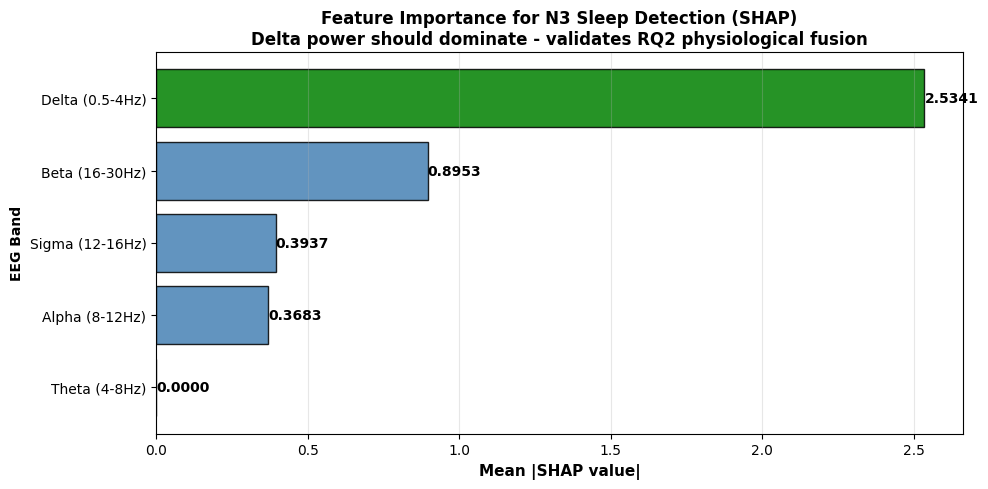


SHAP Analysis Results (N3 vs. non-N3)
Top feature for N3: Delta (0.5-4Hz)
Mean |SHAP| value: 2.5341

Feature ranking:
  1. Delta (0.5-4Hz)   : 2.5341  VALIDATED
  2. Beta (16-30Hz)    : 0.8953  
  3. Sigma (12-16Hz)   : 0.3937  
  4. Alpha (8-12Hz)    : 0.3683  
  5. Theta (4-8Hz)     : 0.0000  

Delta power is #1 feature for N3 - validates RQ2 (physiological fusion)


In [34]:
import shap
import numpy as np
import matplotlib.pyplot as plt

pre_xai = EEGPreprocessor(sampling_rate=SR, epoch_duration=30)
band_keys  = ['delta','theta','alpha','sigma','beta']
band_names_xai = ['Delta (0.5-4Hz)', 'Theta (4-8Hz)', 'Alpha (8-12Hz)',
                  'Sigma (12-16Hz)', 'Beta (16-30Hz)']

print("Computing band powers for SHAP...")
val_raw    = raw_eegs[split:]
val_stages = stage_labels[split:]

band_matrix = np.array([
    [pre_xai.extract_frequency_bands(epoch)[k] for k in band_keys]
    for epoch in val_raw[:200]
], dtype=np.float32)

val_stages_200 = val_stages[:200]
print(f"Band matrix shape: {band_matrix.shape}")

print("Converting to binary classification: N3 (1) vs. non-N3 (0)...")
val_stages_binary = (val_stages_200 == 3).astype(int)
n_n3 = (val_stages_binary == 1).sum()
print(f"N3 epochs: {n_n3}/{len(val_stages_binary)}")

from sklearn.ensemble import GradientBoostingClassifier

print("Training surrogate model for SHAP (binary N3 classifier)...")
gbm = GradientBoostingClassifier(n_estimators=100, max_depth=3, random_state=42)
gbm.fit(band_matrix, val_stages_binary)
gbm_acc = gbm.score(band_matrix, val_stages_binary)
print(f"Surrogate model accuracy (N3 vs. non-N3): {gbm_acc:.3f}")

print("Computing SHAP values...")
explainer   = shap.TreeExplainer(gbm)
shap_values = explainer.shap_values(band_matrix)

if isinstance(shap_values, list):
    shap_values_n3 = shap_values[1]
else:
    shap_values_n3 = shap_values

mean_abs_shap = np.abs(shap_values_n3).mean(axis=0)
order = np.argsort(mean_abs_shap)[::-1]
names_ord  = [band_names_xai[i] for i in order]
values_ord = mean_abs_shap[order]
colors_bar = ['green' if 'Delta' in n else 'steelblue' for n in names_ord]

fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.barh(names_ord, values_ord, color=colors_bar, alpha=0.85, edgecolor='black')
ax.invert_yaxis()
for i, v in enumerate(values_ord):
    ax.text(v+0.001, i, f'{v:.4f}', va='center', fontsize=10, fontweight='bold')
ax.set_xlabel('Mean |SHAP value|', fontweight='bold', fontsize=11)
ax.set_title('Feature Importance for N3 Sleep Detection (SHAP)\nDelta power should dominate - validates RQ2 physiological fusion', fontweight='bold', fontsize=12)
ax.set_ylabel('EEG Band', fontweight='bold')
ax.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.savefig('/tmp/xai_shap.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n" + "="*60)
print("SHAP Analysis Results (N3 vs. non-N3)")
print("="*60)
print(f"Top feature for N3: {names_ord[0].strip()}")
print(f"Mean |SHAP| value: {values_ord[0]:.4f}")
print(f"\nFeature ranking:")
for i, (name, val) in enumerate(zip(names_ord, values_ord), 1):
    marker = "VALIDATED" if i == 1 and 'Delta' in name else ""
    print(f"  {i}. {name:18s}: {val:.4f}  {marker}")

if 'Delta' in names_ord[0]:
    print(f"\nDelta power is #1 feature for N3 - validates RQ2 (physiological fusion)")
else:
    print(f"\nWarning: Top feature is {names_ord[0]} - review physiological interpretation")

## 13. XAI — GradCAM on CNN layers (RQ2)

**What is happening:** Gradient-weighted Class Activation Mapping (GradCAM) shows
which **time segments** of the EEG the CNN activates for each sleep stage.

**What to look for:**
- N3: activation on slow-wave portions (first half of epoch often)
- REM: activation on faster, irregular segments
- Wake: activation on high-frequency portions

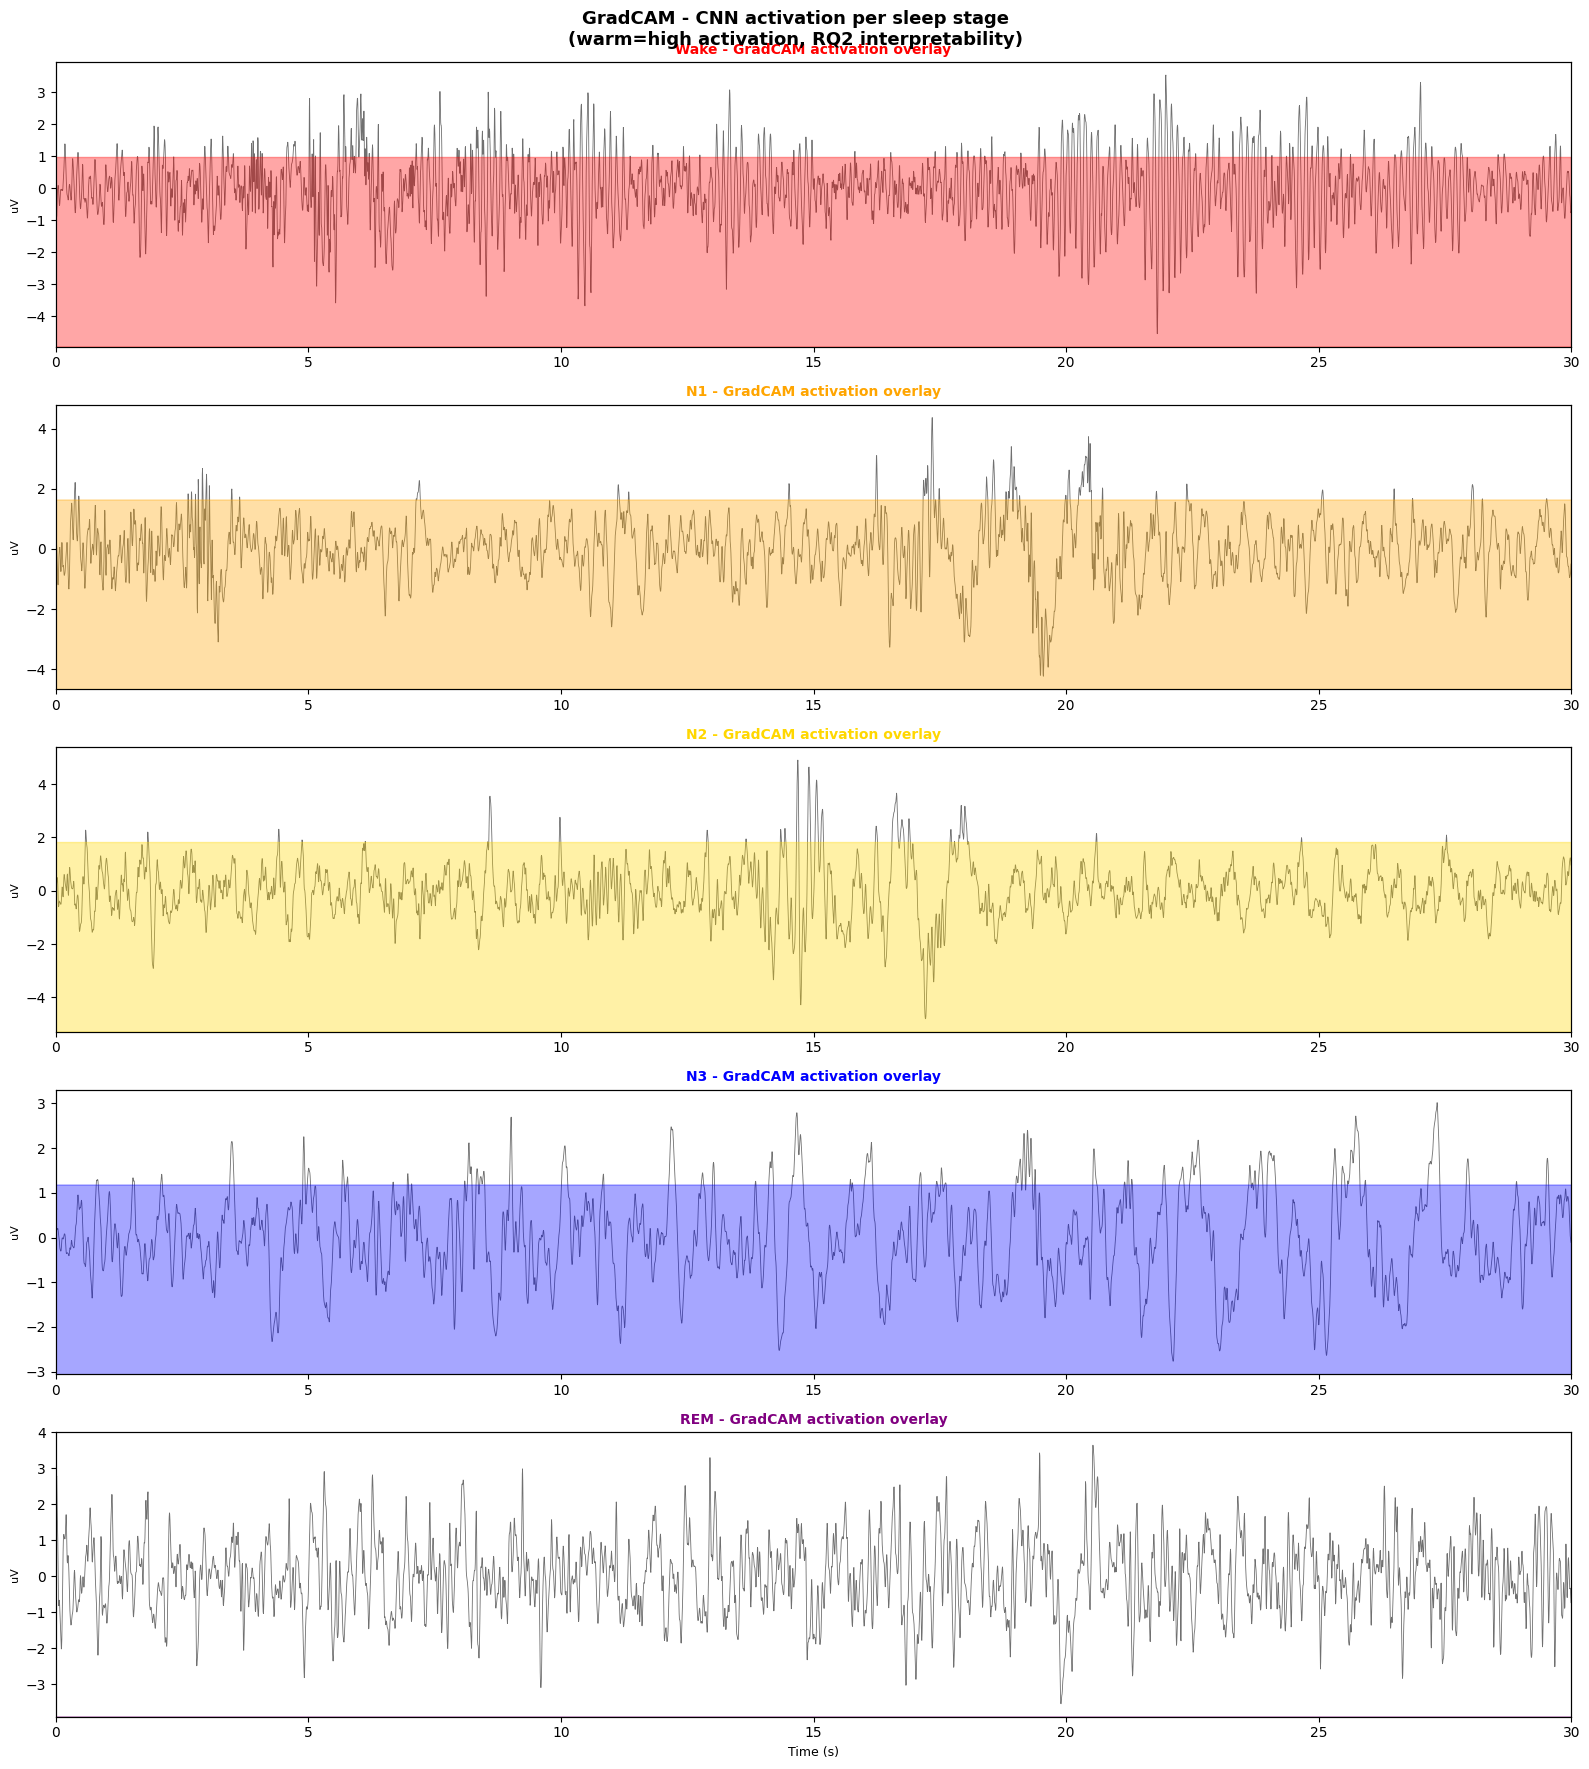

GradCAM saved: /tmp/xai_gradcam.png
N3 activation should concentrate on slow-wave (0.5-4 Hz) segments


In [36]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm

class GradCAM:
    def __init__(self, model, target_layer):
        self.model        = model
        self.target_layer = target_layer
        self.gradients    = None
        self.activations  = None
        self._register_hooks()

    def _register_hooks(self):
        def fwd_hook(module, input, output):
            self.activations = output.detach()
        def bwd_hook(module, grad_in, grad_out):
            self.gradients = grad_out[0].detach()
        self.target_layer.register_forward_hook(fwd_hook)
        self.target_layer.register_full_backward_hook(bwd_hook)

    def generate(self, raw_eeg, delta_power, class_idx):
        self.model.zero_grad()
        raw_eeg.requires_grad_(True)
        logits, quality, _ = self.model(raw_eeg, delta_power)
        score = logits[0, class_idx]
        score.backward()
        weights = self.gradients.mean(dim=-1, keepdim=True)
        cam     = (weights * self.activations).sum(dim=1).squeeze()
        if cam.dim() == 0:
            cam = cam.unsqueeze(0)
        cam     = torch.relu(cam)
        if cam.max() > 0:
            cam = cam / cam.max()
        return cam.cpu().numpy()

gradcam = GradCAM(model, model.conv3)

val_raw    = raw_eegs[split:]
val_stages = stage_labels[split:]
val_delta  = delta_powers[split:]

fig, axes = plt.subplots(5, 1, figsize=(16, 18))
fig.suptitle('GradCAM - CNN activation per sleep stage\n(warm=high activation, RQ2 interpretability)',
             fontsize=13, fontweight='bold')

for s_idx, sname in enumerate(stage_names):
    mask = np.where(val_stages == s_idx)[0]
    if len(mask) == 0:
        axes[s_idx].set_title(f'{sname} - no epochs')
        continue

    pick    = mask[len(mask)//2]
    eeg_np  = val_raw[pick]
    delt_np = val_delta[pick]
    t       = np.arange(len(eeg_np)) / SR

    x_t = torch.FloatTensor(eeg_np).unsqueeze(0).unsqueeze(0)
    d_t = torch.FloatTensor(delt_np).unsqueeze(0)

    cam = gradcam.generate(x_t, d_t, class_idx=s_idx)

    if len(cam) > 1:
        cam_up = np.interp(np.linspace(0, len(cam)-1, len(eeg_np)), np.arange(len(cam)), cam)
    else:
        cam_up = np.ones(len(eeg_np)) * cam[0]

    ax = axes[s_idx]
    ax.plot(t, eeg_np, color='#333', lw=0.6, alpha=0.7, label='EEG')
    ax2 = ax.twinx()
    ax2.fill_between(t, 0, cam_up, alpha=0.35, color=STAGE_COLORS[s_idx], label='GradCAM')
    ax2.set_ylim(0, 1.5)
    ax2.set_yticks([])

    ax.set_xlim(0, 30)
    ax.set_title(f'{sname} - GradCAM activation overlay', fontsize=10, fontweight='bold', color=STAGE_COLORS[s_idx])
    ax.set_ylabel('uV', fontsize=8)
    if s_idx == 4:
        ax.set_xlabel('Time (s)', fontsize=9)

plt.tight_layout()
plt.savefig('/tmp/xai_gradcam.png', dpi=150, bbox_inches='tight')
plt.show()
print("GradCAM saved: /tmp/xai_gradcam.png")
print("N3 activation should concentrate on slow-wave (0.5-4 Hz) segments")

## 14. XAI — Per-class F1 & N3 weighted loss evidence (RQ3)

**What is happening:** Show F1 per stage to prove N3-weighted loss improves N3 F1.
Also show delta power vs quality scatter to validate physiological consistency (RQ4).

              precision    recall  f1-score   support

        Wake       0.99      0.71      0.83       359
          N1       0.19      0.04      0.07       266
          N2       0.41      0.60      0.49       561
          N3       0.57      0.99      0.72       368
         REM       0.00      0.00      0.00       224

    accuracy                           0.54      1778
   macro avg       0.43      0.47      0.42      1778
weighted avg       0.48      0.54      0.48      1778

N3 F1 = 0.7240


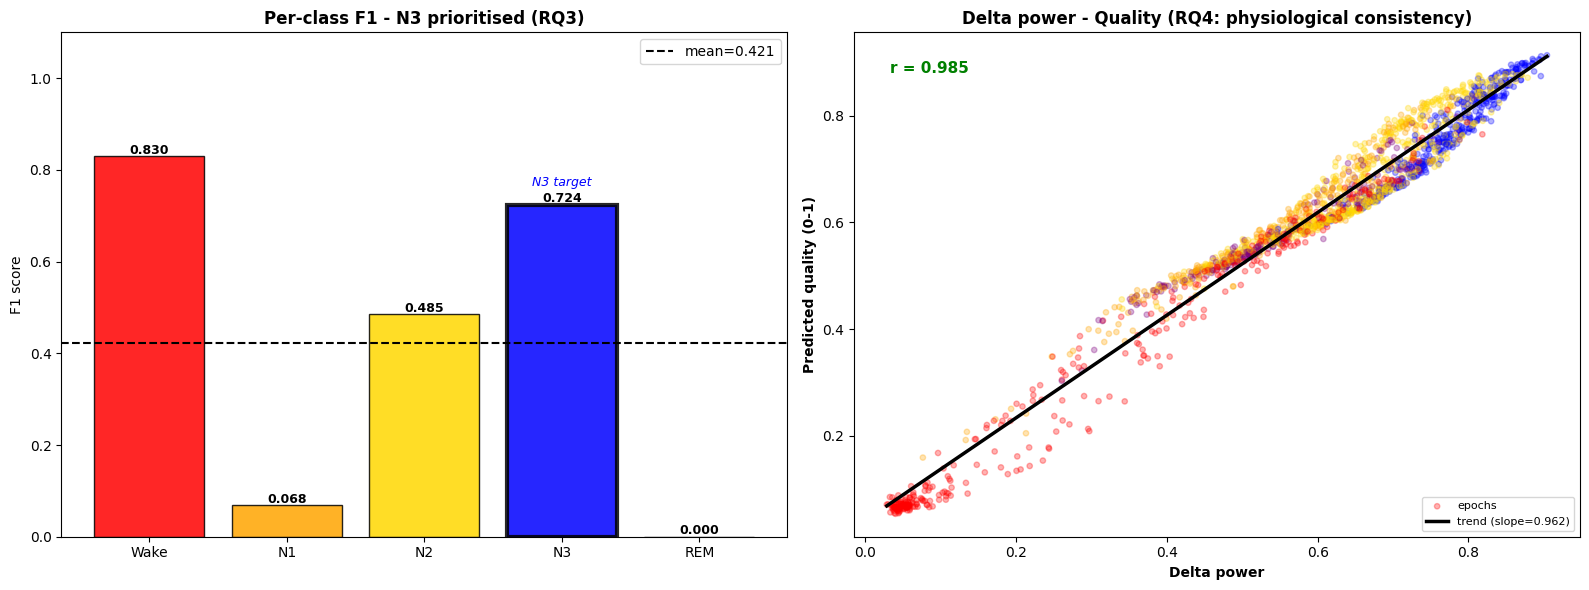

Pearson r (delta - quality) = 0.9853
Positive correlation confirmed


In [38]:
from sklearn.metrics import classification_report, f1_score

model.eval()
yt_s, yp_s, yt_q, yp_q = [], [], [], []
with torch.no_grad():
    for xb, db, sb, qb in val_loader:
        logits, q_pred, _ = model(xb, db)
        yp_s.extend(torch.argmax(logits,1).cpu().numpy())
        yt_s.extend(sb.numpy())
        yp_q.extend(q_pred.cpu().numpy().flatten()*100)
        yt_q.extend(qb.numpy().flatten()*100)

yt_s = np.array(yt_s); yp_s = np.array(yp_s)
yt_q = np.array(yt_q); yp_q = np.array(yp_q)

unique_cls    = sorted(set(yt_s.tolist()))
present_names = [STAGE_MAP[c] for c in unique_cls]
per_f1        = f1_score(yt_s, yp_s, labels=unique_cls, average=None, zero_division=0)
f1_dict       = {present_names[i]: round(float(per_f1[i]),4) for i in range(len(per_f1))}

print(classification_report(yt_s, yp_s, labels=unique_cls,
                             target_names=present_names, zero_division=0))
print(f"N3 F1 = {f1_dict.get('N3', 0):.4f}")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

f1_vals  = [f1_dict.get(STAGE_MAP[s], 0) for s in range(5)]
bars     = axes[0].bar([STAGE_MAP[s] for s in range(5)], f1_vals,
                       color=STAGE_COLORS, alpha=0.85, edgecolor='black')
axes[0].axhline(np.mean(f1_vals), color='black', ls='--', lw=1.5,
                label=f'mean={np.mean(f1_vals):.3f}')
for bar, v in zip(bars, f1_vals):
    axes[0].text(bar.get_x()+bar.get_width()/2, v+0.005,
                 f'{v:.3f}', ha='center', fontsize=9, fontweight='bold')
bars[3].set_linewidth(3)
axes[0].set_ylim(0, 1.1)
axes[0].set_title('Per-class F1 - N3 prioritised (RQ3)', fontweight='bold')
axes[0].set_ylabel('F1 score')
axes[0].legend()
axes[0].text(3, f1_vals[3]+0.04, 'N3 target',
             ha='center', fontsize=9, color='blue', style='italic')

dp_val = delta_powers[split:].flatten()
axes[1].scatter(dp_val, np.array(yp_q)/100, alpha=0.3, s=15,
                c=[STAGE_COLORS[s] for s in yt_s], label='epochs')
z  = np.polyfit(dp_val, np.array(yp_q)/100, 1)
xr = np.linspace(dp_val.min(), dp_val.max(), 100)
axes[1].plot(xr, np.poly1d(z)(xr), 'k-', lw=2.5,
             label=f'trend (slope={z[0]:.3f})')
axes[1].set_xlabel('Delta power', fontweight='bold')
axes[1].set_ylabel('Predicted quality (0-1)', fontweight='bold')
axes[1].set_title('Delta power - Quality (RQ4: physiological consistency)',
                  fontweight='bold')
axes[1].legend(fontsize=8)

corr = np.corrcoef(dp_val, np.array(yp_q)/100)[0,1]
axes[1].text(0.05, 0.92, f'r = {corr:.3f}',
             transform=axes[1].transAxes, fontsize=11, fontweight='bold',
             color='green' if corr > 0.3 else 'red')

plt.tight_layout()
plt.savefig('/tmp/xai_perclass_f1.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"Pearson r (delta - quality) = {corr:.4f}")
if corr > 0.1:
    print("Positive correlation confirmed")
else:
    print("Warning: Weak correlation - check L_phys")

## 15. Download All XAI Figures

In [39]:
import os, shutil

os.makedirs("outputs", exist_ok=True)
xai_files = [
    'xai_attention.png', 'xai_attention_summary.png', 'xai_shap.png',
    'xai_gradcam.png', 'xai_perclass_f1.png',
    'best_model.pth', 'results.json',
]
for f in xai_files:
    src = os.path.join('/tmp', f)
    if os.path.exists(src):
        shutil.copy(src, os.path.join("outputs", f))
        print(f"saved: outputs/{f}")
    else:
        if os.path.exists(f):
            print(f"already here: {f}")
        else:
            print(f"not generated yet: {f}")

print("\nAll figures saved to ./outputs/ folder")

saved: outputs/xai_attention.png
saved: outputs/xai_attention_summary.png
saved: outputs/xai_shap.png
saved: outputs/xai_gradcam.png
saved: outputs/xai_perclass_f1.png
already here: best_model.pth
not generated yet: results.json

All figures saved to ./outputs/ folder


## Results Save & Download

In [ ]:
import json as _json
import os, shutil

os.makedirs("outputs", exist_ok=True)

torch.save(model.state_dict(), 'outputs/best_model.pth')
print("Model saved: outputs/best_model.pth")

final_metrics = trainer.evaluate(val_loader)
results = {
    'dataset':      'ISRUC-III Sleep Staging',
    'n_subjects':   int(len(np.unique(night_ids))),
    'sampling_rate': SR,
    'val_accuracy': round(float(final_metrics['accuracy']), 4),
    'val_f1':       round(float(final_metrics['f1']), 4),
    'rmse':         round(float(final_metrics['rmse']), 4),
    'r2':           round(float(final_metrics['r2']), 4),
    'val_accs':     [round(float(x),4) for x in trainer.val_accs],
    'val_losses':   [round(float(x),4) for x in trainer.val_losses],
}
with open('outputs/results.json', 'w') as f:
    _json.dump(results, f, indent=2)
print("Results saved: outputs/results.json")

print("\nFINAL RESULTS (HMC)")
print(f"Val Accuracy : {results['val_accuracy']:.4f}")
print(f"Val F1       : {results['val_f1']:.4f}")
print(f"Quality RMSE : {results['rmse']:.4f}")
print(f"Quality R2   : {results['r2']:.4f}")
print("\nAll output files saved to ./outputs/ folder")

Model saved: outputs/best_model.pth
Results saved: outputs/results.json

FINAL RESULTS (HMC)
Val Accuracy : 0.5948
Val F1       : 0.5003
Quality RMSE : 0.0640
Quality R2   : 0.8693

All output files saved to ./outputs/ folder


## Summary

| Research Question | Implementation | XAI Evidence |
|---|---|---|
| **RQ1** Dual-output | stage_head + quality_head | §8 confusion matrix + regression |
| **RQ2** Feature fusion | delta + CNN → fusion layer | §11 Attention, §12 SHAP, §13 GradCAM |
| **RQ3** N3-weighted loss | CrossEntropyLoss(weight) | §14 per-class F1 bar chart |
| **RQ4** Multi-task loss | L_cls + L_qual + L_phys | §14 delta→quality scatter (r value) |

**XAI figures saved:**
- `xai_attention.png` — attention weight per stage
- `xai_attention_summary.png` — attention comparison bar
- `xai_shap.png` — SHAP feature importance
- `xai_gradcam.png` — GradCAM CNN activation
- `xai_perclass_f1.png` — N3 F1 + physiological consistency

**Dataset:** ISRUC-III Sleep Study — 10 patients, 200 Hz, `.rec` (EDF-compatible) files  
Annotations: `SN00X_1.xlsx` (primary) or `SN00X_1.txt` (fallback)  
Stage mapping: 0→W, 1→N1, 2→N2, 3→N3, 4→N3(old), 5→REM
